# Home Credit Default Risk Dataset Project

# Part 1 - Exploring Application Data.

## Introduction

Many people struggle to get loans due to insufficient or non-existent credit histories. They are often excluded from traditional lending systems and are especially vulnerable to exploitation by unregulated, untrustworthy or predatory lenders.

Home Credit strives to broaden financial inclusion for the unbanked population by providing a positive and safe borrowing experience. By leveraging alternative data sources—such as telco usage, payment behavior, and transaction history—they aim to responsibly extend credit access to underserved populations. Their goal is to ensure that loans are offered only to individuals who can repay them, and to structure the terms in a way that promotes long-term financial health.

While Home Credit is currently using various statistical and machine learning methods to make these predictions, they challenge data scientists and machine learning practitioners to push these techniques even further. Doing so will ensure that clients capable of repayment are not rejected and that loans are given with a principal, maturity, and repayment calendar that will empower their clients to be successful. (https://www.kaggle.com/competitions/home-credit-default-risk/overview)

*Project - a brilliant startup idea*

Motivated by the real-world impact of such systems, a friend and I decided to turn this into a startup idea: offer credit risk evaluation as a service for retail banks. Like many successful teams, we divided responsibilities:
- My friend is responsible for sales and operations,
- while I am responsible for everything product-related, from planning and data analysis to building robust ML-driven solutions.

As a first step, I downloaded and explored the Home Credit dataset to begin developing a proof of concept.
We agreed to develop a portfolio of machine learning models. This way, when we meet with potential banking partners, we can demonstrate flexibility, adaptability, and a deep understanding of credit risk from multiple perspectives.

**Dataset information**

Data is taken from Kaggle https://www.kaggle.com/competitions/home-credit-default-risk/data

**Project**

Home Credit Default Risk competition dataset is used for Machine Learning Capstone Project project of Machine Learning module sprint 4. Data analysis is done using python and pandas library. Modeling is done using scikit-learn and optuna. For visualization matplotlib and seaborn libraries were used. The project is done using Jupyter notebooks (4.2.4). The models were deployed on Google Cloud, using Docker.

The project is done using python (version 3.11.4), numpy (2.0.1), pandas (2.2.3), seaborn (0.13.2), matplotlib (3.9.1), missingno (0.5.2), duckdb (1.0.0), dill (0.4.0), fastapi (0.115.2), uvicorn (0.31.1), scikit-learn (1.5.1), xgboost (3.0.5), lightgbm (4.5.0), optuna (4.4.0), scipy (1.14.0) and statsmodels (0.14.2) libraries.

**Project goal**

Project Goal: Build and Compare Multiple ML Models

**Plan**

I will explore these points:
- Exploratory data analysis.
- Engineering features.
- Checking if the features are statistically important using hypothesis testing.
- Building and evaluating multiple models.
- Deploying machine learning models.

**Structure**
The project will be broken into several notebooks:
- Part 1 - Home Credit Project: exploring application data.
- Part 2 - Analysis of Supplementary Data: exploring additional data provided.
- Part 3 - All Data and Statistical Inference: connecting all of the data, correlation, hypothesis testing.
- Part 4 - Model training (XGBoost & LightGBM) and cloud deployment

## Importing Dataset and Packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import missingno as msno
import duckdb as db
from sklearn.preprocessing import OneHotEncoder
from scipy import stats
from scripts import *

pd.set_option('display.max_rows', 300)

### Importing Data

In [2]:
app_test = pd.read_csv('home-credit-default-risk/application_test.csv')
app_test.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
app_train = pd.read_csv('home-credit-default-risk/application_train.csv')
app_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
HomeCredit_columns_description = pd.read_csv(
    'home-credit-default-risk/HomeCredit_columns_description.csv', encoding="ISO-8859-1", index_col=0
)
HomeCredit_columns_description.head()

,Table,Row,Description,Special
1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN


# Application data

## Checking For Nulls and Duplicates

### Duplicates

In [5]:
app_test.duplicated().any()

np.False_

In [6]:
app_test.columns.duplicated().any()

np.False_

In [7]:
app_train.duplicated().any()

np.False_

In [8]:
app_train.columns.duplicated().any()

np.False_

### Missing Values

In [9]:
app_trainnullresults = app_train.isnull().sum()
rows_nr = app_train.shape[0]
for item in app_train.columns:
    missing_nr = app_trainnullresults[item]
    if missing_nr > 0:
        missing_perc = count_percentage(missing_nr, rows_nr, round_value=4)
        print(f'The percentage of missing {item} values is {missing_perc}%.')

The percentage of missing AMT_ANNUITY values is 0.0039%.
The percentage of missing AMT_GOODS_PRICE values is 0.0904%.
The percentage of missing NAME_TYPE_SUITE values is 0.4201%.
The percentage of missing OWN_CAR_AGE values is 65.9908%.
The percentage of missing OCCUPATION_TYPE values is 31.3455%.
The percentage of missing CNT_FAM_MEMBERS values is 0.0007%.
The percentage of missing EXT_SOURCE_1 values is 56.3811%.
The percentage of missing EXT_SOURCE_2 values is 0.2146%.
The percentage of missing EXT_SOURCE_3 values is 19.8253%.
The percentage of missing APARTMENTS_AVG values is 50.7497%.
The percentage of missing BASEMENTAREA_AVG values is 58.516%.
The percentage of missing YEARS_BEGINEXPLUATATION_AVG values is 48.781%.
The percentage of missing YEARS_BUILD_AVG values is 66.4978%.
The percentage of missing COMMONAREA_AVG values is 69.8723%.
The percentage of missing ELEVATORS_AVG values is 53.296%.
The percentage of missing ENTRANCES_AVG values is 50.3488%.
The percentage of missing 

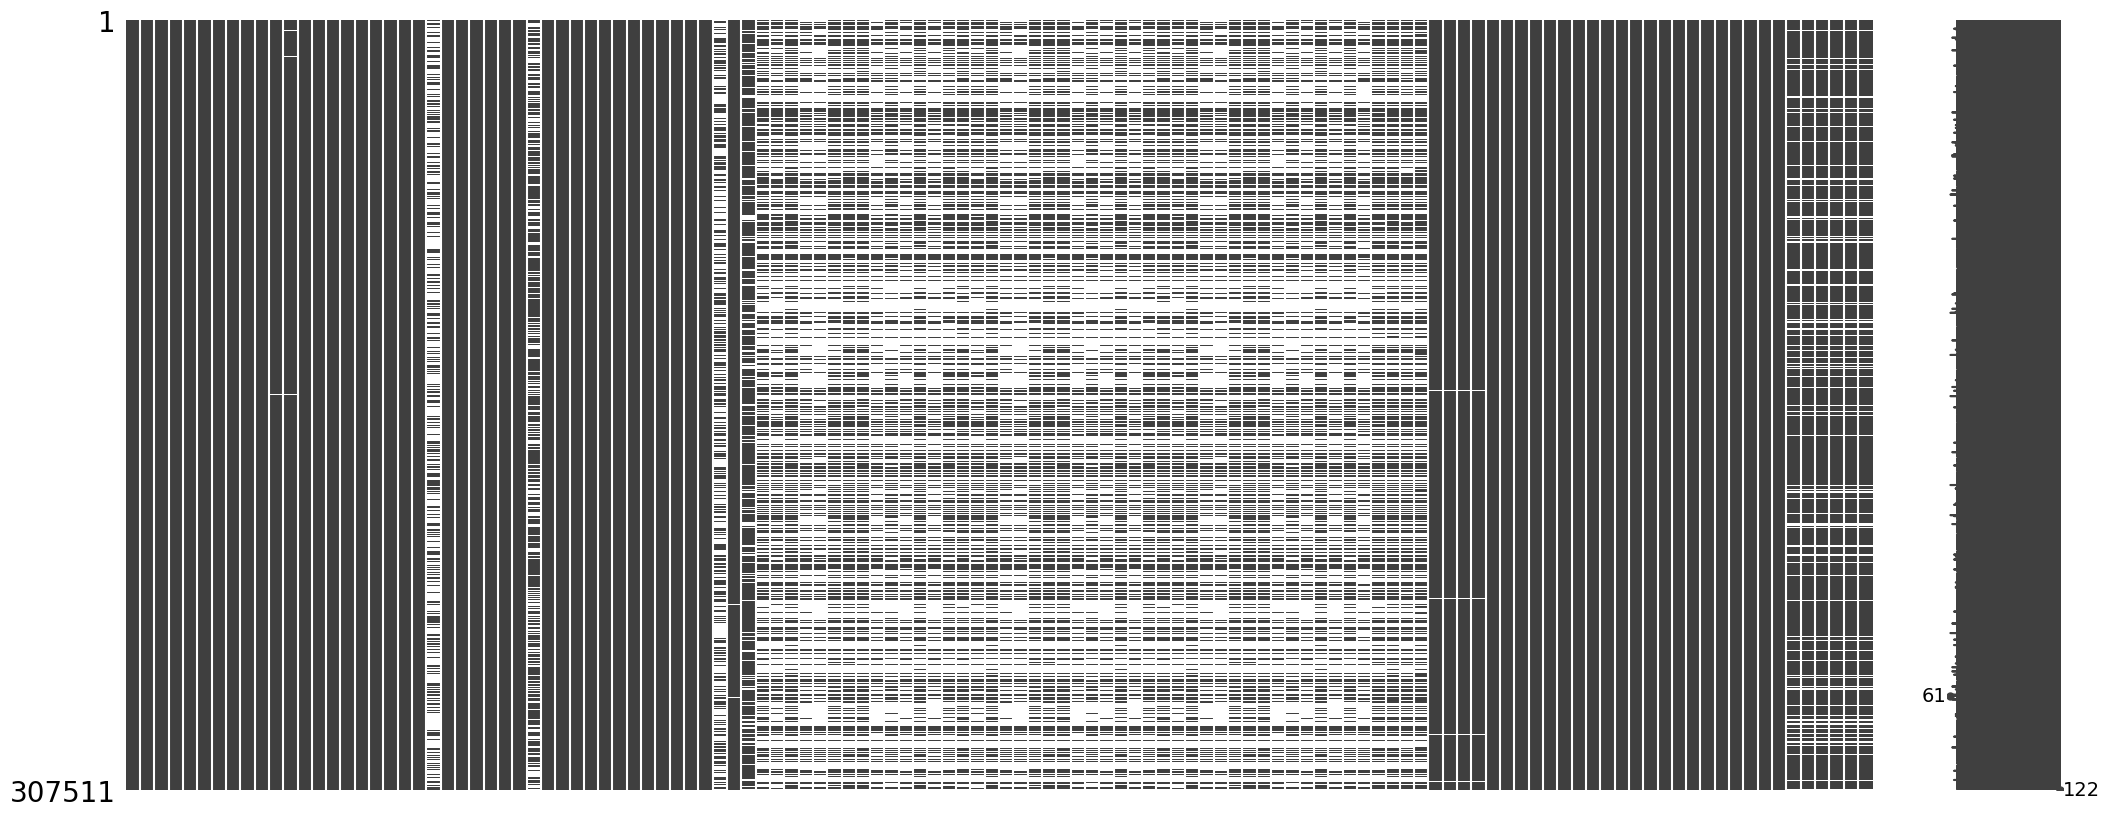

In [10]:
%matplotlib inline

msno.matrix(app_train);

In certain features there are a lot of missing values. It will be investigated further.

#### From AMT_ANNUITY to CNT_FAM_MEMBERS

In [11]:
app_train['AMT_ANNUITY'].isnull().groupby(app_train['NAME_INCOME_TYPE']).mean()

NAME_INCOME_TYPE
Businessman             0.000000
Commercial associate    0.000042
Maternity leave         0.000000
Pensioner               0.000000
State servant           0.000138
Student                 0.000000
Unemployed              0.000000
Working                 0.000038
Name: AMT_ANNUITY, dtype: float64

There are some missing records for AMT_ANNUITY. An Annuity is a loan with a monthly repayment, which is always the same amount. In other words, you pay the same sum each month. Missing values might be linked to flexible repayment schedules, or special loan terms. There are only very few missing values, and there doesn't seem to be any pattern. Therefore, it will not be investigated further.

In [12]:
app_train['AMT_GOODS_PRICE'].isnull().groupby(app_train['NAME_CONTRACT_TYPE']).mean()

NAME_CONTRACT_TYPE
Cash loans         0.000000
Revolving loans    0.009495
Name: AMT_GOODS_PRICE, dtype: float64

There are only missing values in revolving loans. It could be explained by some type of behavior. However, the percentage of missing values is still very low (around 1% of revolving loans), therefore it will not be investigated any further.

In [13]:
app_train.groupby(app_train['NAME_TYPE_SUITE'].isna())['TARGET'].mean()

NAME_TYPE_SUITE
False    0.080841
True     0.054180
Name: TARGET, dtype: float64

In [14]:
app_train['NAME_TYPE_SUITE'].isnull().groupby(app_train['NAME_FAMILY_STATUS']).mean()

NAME_FAMILY_STATUS
Civil marriage          0.003829
Married                 0.003991
Separated               0.003794
Single / not married    0.005369
Unknown                 1.000000
Widow                   0.004538
Name: NAME_TYPE_SUITE, dtype: float64

NAME_TYPE_SUITE indicates who has been accompaning the clients. It looks like sometimes the data was not collected or not provided. All whose Family status is unknown did not have accompaning person collected. It is also likely that they were alone therefore no information was registered.

In [15]:
owncar_counts = app_train['FLAG_OWN_CAR'].value_counts()
dontowncarperc = count_percentage(owncar_counts['N'], owncar_counts.sum())
print(f'The percentage of clients without a car: {dontowncarperc}%')

The percentage of clients without a car: 65.99%


In [16]:
query = '''
SELECT * 
FROM app_train
WHERE FLAG_OWN_CAR = 'N' AND OWN_CAR_AGE IS NOT NULL
'''

db.sql(query).df().shape

(0, 122)

The percentage of missing values in OWN_CAR_AGE is the same as for clients without cars. All null values in OWN_CAR_AGE are due to clients not owning a car.

In [17]:
app_train['OCCUPATION_TYPE'].value_counts()

OCCUPATION_TYPE
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

In [18]:
app_train['OCCUPATION_TYPE'].isnull().groupby(app_train['NAME_INCOME_TYPE']).mean()

NAME_INCOME_TYPE
Businessman             0.200000
Commercial associate    0.171705
Maternity leave         0.200000
Pensioner               0.999910
State servant           0.174492
Student                 0.277778
Unemployed              1.000000
Working                 0.156953
Name: OCCUPATION_TYPE, dtype: float64

In [19]:
app_train['OCCUPATION_TYPE'].isnull().groupby(app_train['ORGANIZATION_TYPE']).mean()

ORGANIZATION_TYPE
Advertising               0.160839
Agriculture               0.150774
Bank                      0.092940
Business Entity Type 1    0.218917
Business Entity Type 2    0.214631
Business Entity Type 3    0.210863
Cleaning                  0.280769
Construction              0.097009
Culture                   0.218997
Electricity               0.121053
Emergency                 0.176786
Government                0.200211
Hotel                     0.255694
Housing                   0.140974
Industry: type 1          0.147257
Industry: type 10         0.137615
Industry: type 11         0.193417
Industry: type 12         0.146341
Industry: type 13         0.164179
Industry: type 2          0.146288
Industry: type 3          0.133618
Industry: type 4          0.201824
Industry: type 5          0.181970
Industry: type 6          0.250000
Industry: type 7          0.164499
Industry: type 8          0.083333
Industry: type 9          0.155879
Insurance                 0.105528
Ki

There are some trends for missing 'OCCUPATION_TYPE' values. For example there is no cathegory for unemployed. Not employed will be imputed for pensioners, unemployed, students and maternity leave. Some self-employed people might not have specific title, therefore the rest of missing values will be filled with uknown.

Missing values for CNT_FAM_MEMBERS will not be investigated any further as there is only 0.0007% missing and it's unlikelly that there is a pattern.

#### EXT_SOURCE_1 - 3

In [20]:
temp_list = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
lamb = lambda x: x.isnull().mean()
app_train[temp_list].isnull().groupby(app_train['NAME_INCOME_TYPE']).mean()

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
NAME_INCOME_TYPE,,,
Businessman,0.600000,0.000000,0.600000
Commercial associate,0.498485,0.001969,0.207646
Maternity leave,0.200000,0.000000,1.000000
Pensioner,0.767891,0.002818,0.199650
State servant,0.492098,0.002212,0.148781
Student,0.500000,0.000000,0.222222
Unemployed,0.681818,0.000000,0.772727
Working,0.531920,0.001984,0.200159


In [21]:
print(app_train.groupby(app_train['EXT_SOURCE_1'].isnull())['TARGET'].mean())
print(app_train.groupby(app_train['EXT_SOURCE_2'].isnull())['TARGET'].mean())
app_train.groupby(app_train['EXT_SOURCE_3'].isnull())['TARGET'].mean()

EXT_SOURCE_1
False    0.074955
True     0.085195
Name: TARGET, dtype: float64
EXT_SOURCE_2
False    0.080733
True     0.078788
Name: TARGET, dtype: float64


EXT_SOURCE_3
False    0.077665
True     0.093119
Name: TARGET, dtype: float64

These columns (EXT_SOURCE_1, EXT_SOURCE_2, and EXT_SOURCE_3) in the Home Credit Default Risk dataset are external credit scores. 
Missing values suggest that these people do not have credit history from these sources.
- For source 1, there are many missing values accors all of the income type categories. There seems to be a higher default risk for missing the target.
- There aren't that many of missing values in the source 2, and missing values does not seem to influence the target.
- Source 3 also has a lot of missing values, and there are some income categories which have more missing values than other: 100% of people in maternity leave, 77% of unemployed, 60% of businessmen. There seems to be a higher default risk for missing the target.

It seems to be a good idea to create columns to indicate which values were missing, for sources 1 and 3.

#### Information Where Client Lives (from APARTMENTS_AVG to EMERGENCYSTATE_MODE)

In [22]:
building_avg = [
    'APARTMENTS_AVG',
    'BASEMENTAREA_AVG',
    'YEARS_BEGINEXPLUATATION_AVG',
    'YEARS_BUILD_AVG',
    'COMMONAREA_AVG',
    'ELEVATORS_AVG',
    'ENTRANCES_AVG',
    'FLOORSMAX_AVG',
    'FLOORSMIN_AVG',
    'LANDAREA_AVG',
    'LIVINGAPARTMENTS_AVG',
    'LIVINGAREA_AVG',
    'NONLIVINGAPARTMENTS_AVG',
    'NONLIVINGAREA_AVG',
]

building_mod = [
    'APARTMENTS_MODE',
    'BASEMENTAREA_MODE',
    'YEARS_BEGINEXPLUATATION_MODE',
    'YEARS_BUILD_MODE',
    'COMMONAREA_MODE',
    'ELEVATORS_MODE',
    'ENTRANCES_MODE',
    'FLOORSMAX_MODE',
    'FLOORSMIN_MODE',
    'LANDAREA_MODE',
    'LIVINGAPARTMENTS_MODE',
    'LIVINGAREA_MODE',
    'NONLIVINGAPARTMENTS_MODE',
    'NONLIVINGAREA_MODE',
]

building_med = [
    'APARTMENTS_MEDI',
    'BASEMENTAREA_MEDI',
    'YEARS_BEGINEXPLUATATION_MEDI',
    'YEARS_BUILD_MEDI',
    'COMMONAREA_MEDI',
    'ELEVATORS_MEDI',
    'ENTRANCES_MEDI',
    'FLOORSMAX_MEDI',
    'FLOORSMIN_MEDI',
    'LANDAREA_MEDI',
    'LIVINGAPARTMENTS_MEDI',
    'LIVINGAREA_MEDI',
    'NONLIVINGAPARTMENTS_MEDI',
    'NONLIVINGAREA_MEDI',
]

building_other = ['FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'TOTALAREA_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']

In [23]:
index = range(len(building_avg))
list_not_null = []
for i in index:
    query = f'''
    SELECT * 
    FROM app_train
    WHERE {building_avg[i]} IS NULL AND {building_mod[i]} IS NOT NULL
    '''
    res_mod = db.sql(query).df().shape[0]

    query = f'''
    SELECT * 
    FROM app_train
    WHERE {building_avg[i]} IS NULL AND {building_med[i]} IS NOT NULL
    '''
    res_med = db.sql(query).df().shape[0]

    if res_med or res_mod > 0:
        list_not_null.append(i)

if len(list_not_null) > 0:
    print(list_not_null)
else:
    print('Averages, modus and medians are null together.')

Averages, modus and medians are null together.


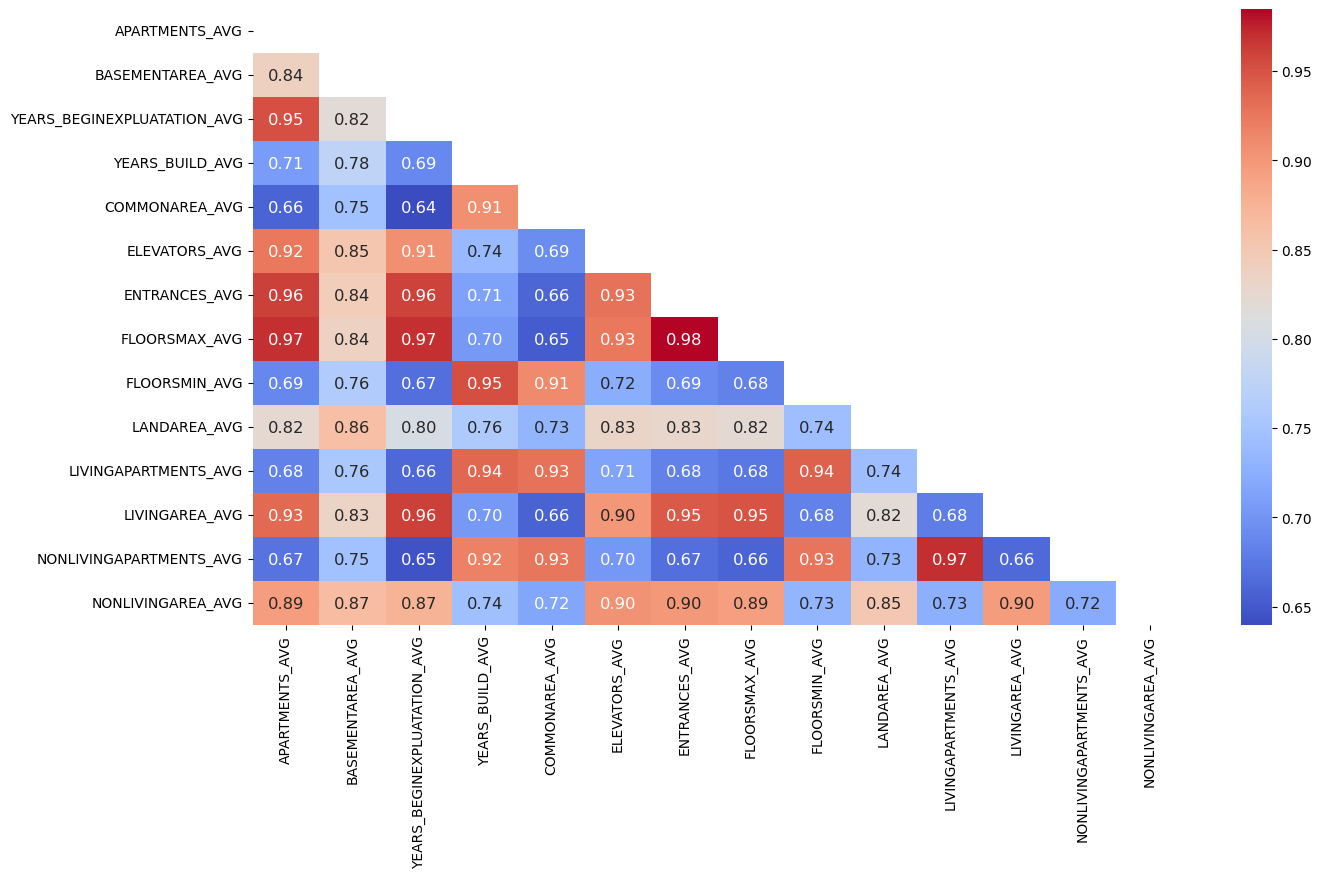

In [24]:
df = kendalltau_f(building_avg, building_avg, app_train.isnull())

fig = plt.figure(figsize=(15, 8))

# To make a triangle mask
mask = np.triu(np.ones_like(df))

corr_plot = sns.heatmap(
    df,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    annot=True,
    annot_kws={"size": 44 / np.sqrt(len(df))},
    fmt=".2f",
    mask=mask,
)

The missing data isn’t random - it follows a strong pattern among building-related features. Some reasons for missing data is that some building do not have complete records, such as older buildings. Some features might only exist for larger or newer buildings. Non-residential properties might not have APARTMENTS_AVG or LIVINGAREA_AVG.

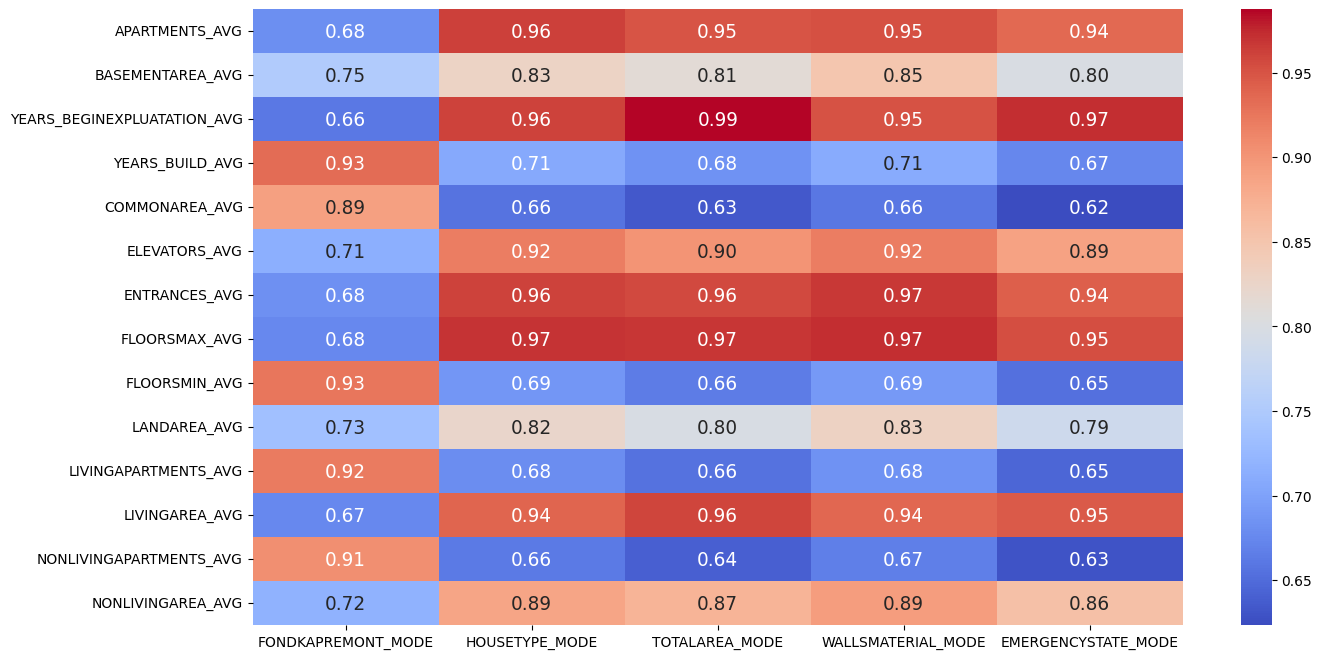

In [25]:
df = kendalltau_f(building_avg, building_other, app_train.isnull())

fig = plt.figure(figsize=(15, 8))

corr_plot = sns.heatmap(
    df,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    annot=True,
    annot_kws={"size": 50 / np.sqrt(len(df))},
    fmt=".2f",
)

Building specific features are often co-occur with missing housing attributes. It can be once again due to missing records for the houses. There also could be some features missing which the building does not have, for example, certain house types (e.g., small buildings, single-family homes) may not have ELEVATORS_AVG, causing structured missingness. 

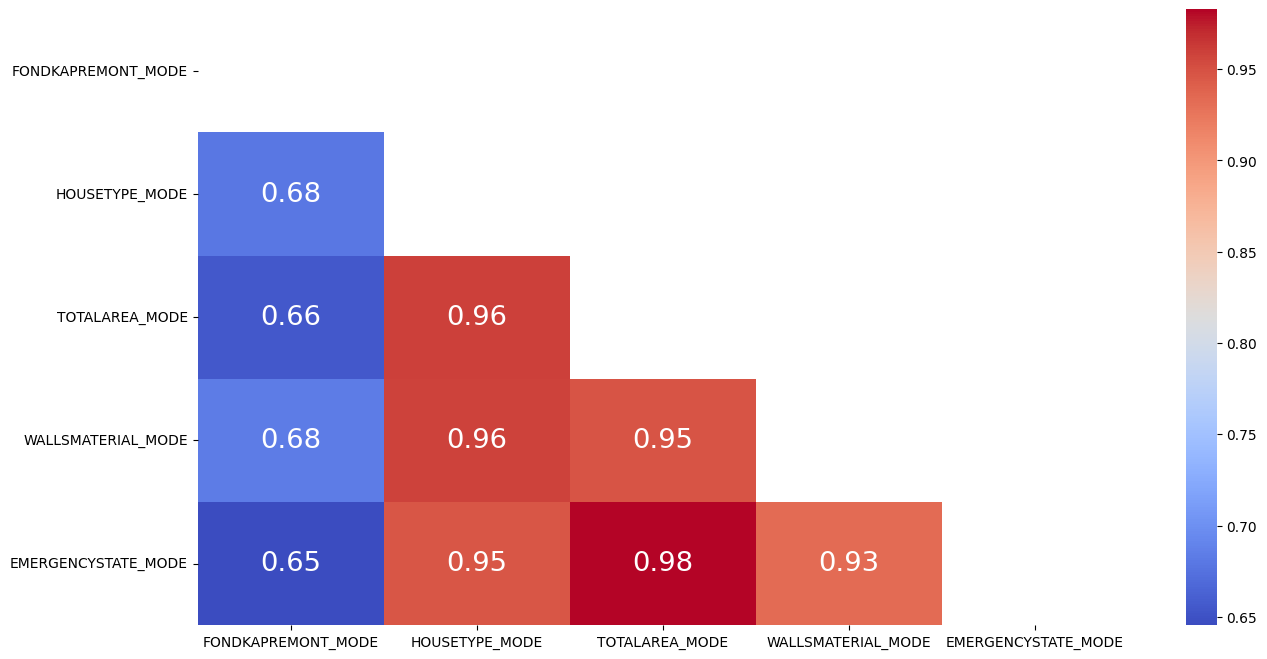

In [26]:
df = kendalltau_f(building_other, building_other, app_train.isnull())

fig = plt.figure(figsize=(15, 8))

# To make a triangle mask
mask = np.triu(np.ones_like(df))

corr_plot = sns.heatmap(
    df,
    cmap=sns.color_palette("coolwarm", as_cmap=True),
    annot=True,
    annot_kws={"size": 44 / np.sqrt(len(df))},
    fmt=".2f",
    mask=mask,
)

TOTALAREA_MODE, HOUSETYPE_MODE, and WALLSMATERIAL_MODE are highly correlated. If one is missing, it's likely the others are too. It might be due to missing records. FONDKAPREMONT_MODE is less correlated with other values. FONDKAPREMONT_MODE data might be missing due to administrative gaps (e.g., private buildings not covered by government repair programs). For FONDKAPREMONT_MODE seems to be more random with missing values. 

In [27]:
for item in building_avg:
    print(app_train.groupby(app_train[item].isnull())['TARGET'].mean())

APARTMENTS_AVG
False    0.069594
True     0.091535
Name: TARGET, dtype: float64
BASEMENTAREA_AVG
False    0.068881
True     0.089128
Name: TARGET, dtype: float64
YEARS_BEGINEXPLUATATION_AVG
False    0.069947
True     0.092049
Name: TARGET, dtype: float64
YEARS_BUILD_AVG
False    0.068664
True     0.086807
Name: TARGET, dtype: float64
COMMONAREA_AVG
False    0.069102
True     0.085742
Name: TARGET, dtype: float64
ELEVATORS_AVG
False    0.069002
True     0.091006
Name: TARGET, dtype: float64
ENTRANCES_AVG
False    0.069517
True     0.091786
Name: TARGET, dtype: float64
FLOORSMAX_AVG
False    0.069655
True     0.091910
Name: TARGET, dtype: float64
FLOORSMIN_AVG
False    0.068950
True     0.086311
Name: TARGET, dtype: float64
LANDAREA_AVG
False    0.069812
True     0.088198
Name: TARGET, dtype: float64
LIVINGAPARTMENTS_AVG
False    0.068882
True     0.086214
Name: TARGET, dtype: float64
LIVINGAREA_AVG
False    0.069953
True     0.091422
Name: TARGET, dtype: float64
NONLIVINGAPARTMENTS_AVG


In [28]:
app_train.groupby(app_train[building_avg].isna().any(axis=1))['TARGET'].mean()

False    0.069563
True     0.084760
Name: TARGET, dtype: float64

In [29]:
app_train.groupby(app_train[building_avg].isna().all(axis=1))['TARGET'].mean()

False    0.070000
True     0.092171
Name: TARGET, dtype: float64

In [30]:
for item in building_other:
    print(app_train.groupby(app_train[item].isnull())['TARGET'].mean())

FONDKAPREMONT_MODE
False    0.068919
True     0.086188
Name: TARGET, dtype: float64
HOUSETYPE_MODE
False    0.069870
True     0.091512
Name: TARGET, dtype: float64
TOTALAREA_MODE
False    0.069896
True     0.092339
Name: TARGET, dtype: float64
WALLSMATERIAL_MODE
False    0.069815
True     0.091281
Name: TARGET, dtype: float64
EMERGENCYSTATE_MODE
False    0.070025
True     0.092607
Name: TARGET, dtype: float64


In [31]:
app_train.groupby(app_train[building_other].isna().any(axis=1))['TARGET'].mean()

False    0.068973
True     0.086093
Name: TARGET, dtype: float64

In [32]:
app_train.groupby(app_train[building_other].isna().all(axis=1))['TARGET'].mean()

False    0.070025
True     0.092607
Name: TARGET, dtype: float64

If a feature is missing there seems to be a higher default risk for missing the target.

#### Rest of Missing Values (from OBS_30_CNT_SOCIAL_CIRCLE)

In [33]:
# Checking if all of these values are missing together.

query = '''
SELECT * 
FROM app_train
WHERE DEF_60_CNT_SOCIAL_CIRCLE IS NULL AND OBS_60_CNT_SOCIAL_CIRCLE IS NOT NULL
'''

assert db.sql(query).df().shape[0] == 0

query = '''
SELECT * 
FROM app_train
WHERE DEF_30_CNT_SOCIAL_CIRCLE IS NULL AND OBS_30_CNT_SOCIAL_CIRCLE IS NOT NULL
'''

assert db.sql(query).df().shape[0] == 0

query = '''
SELECT * 
FROM app_train
WHERE OBS_60_CNT_SOCIAL_CIRCLE IS NULL AND DEF_30_CNT_SOCIAL_CIRCLE IS NOT NULL
'''

assert db.sql(query).df().shape[0] == 0

Missing values in DEF_60_CNT_SOCIAL_CIRCLE, OBS_60_CNT_SOCIAL_CIRCLE, DEF_30_CNT_SOCIAL_CIRCLE and OBS_30_CNT_SOCIAL_CIRCLE are all missing together. The values might be missing due to that the applicant has no known social circle, data is not retrieved, not collected or they live in rural or isolated area.

Missing values for DAYS_LAST_PHONE_CHANGE will not be investigated any further as there is only 0.0003% missing and it's unlikelly that there is a pattern.

In [34]:
bureau_cols = [col for col in app_train.columns if 'AMT_REQ_CREDIT_BUREAU' in col]

# Checking if all missing values are missing together
# for AMT_REQ_CREDIT_BUREAU_* columns

missing_all = app_train[bureau_cols].isnull().all(axis=1).mean()
missing_any = app_train[bureau_cols].isnull().any(axis=1).mean()
missing_all == missing_any

np.True_

In [35]:
print(app_train.groupby(app_train[bureau_cols[0]].isnull())['TARGET'].mean())

AMT_REQ_CREDIT_BUREAU_HOUR
False    0.077194
True     0.103374
Name: TARGET, dtype: float64


In [36]:
app_train[app_train[bureau_cols].isnull().all(axis=1)]['NAME_INCOME_TYPE'].value_counts(normalize=True)

NAME_INCOME_TYPE
Working                 0.525711
Commercial associate    0.236301
Pensioner               0.184181
State servant           0.053084
Unemployed              0.000409
Businessman             0.000145
Maternity leave         0.000096
Student                 0.000072
Name: proportion, dtype: float64

The majority of applicants missing credit bureau inquiry data are “Working” individuals — this goes against the assumption that only people without a financial history (e.g., students or pensioners) would have these missing. It's plausible these people simply had no inquiries. Not having any data also increases chance of default.

#### Filling Missing Values

DAYS_EMPLOYED represents the number of days a person has been employed, with negative values indicating how many days before the application they began employment. However, the value 365243 is used as a special flag to represent applicants who are not currently employed — it’s not a real duration. Based on it we can prefill occupation type as not employed for

In [37]:
mask = app_train.DAYS_EMPLOYED == 365243
app_train['NAME_INCOME_TYPE'][mask].unique()

app_train.loc[mask, 'OCCUPATION_TYPE'] = app_train.loc[mask, 'OCCUPATION_TYPE'].fillna('Not employed')

# Rest is going to filled with Unknown.
app_train['OCCUPATION_TYPE'] = app_train['OCCUPATION_TYPE'].fillna('Unknown')

app_train['OCCUPATION_TYPE'].isnull().sum()

np.int64(0)

Rest of missing values will be filled during modeling part, using impute strategies.

## Exploring data

### Features

application_{train|test}.csv
- This is the main table, broken into two files for Train (with TARGET) and Test
(without TARGET).
- Static data for all applications. One row represents one loan in our data
sample.

In [38]:
query = '''
SELECT * 
FROM HomeCredit_columns_description
WHERE "Table" = 'application_{train|test}.csv'
'''

app_traintest_info = db.sql(query).df()
app_traintest_info

,Table,Row,Description,Special
0,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,None
1,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,None
2,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,None
3,application_{train|test}.csv,CODE_GENDER,Gender of the client,None
4,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,None
5,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,None
6,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,None
7,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,None
8,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,None
9,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,None


In [39]:
app_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [40]:
app_train.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,1.000020e+05,189145.500000,278202.000000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.000000e+00,0.000000,0.000000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.000000e+00,0.000000,0.000000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,4.500000e+04,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1.615500e+03,16524.000000,24903.000000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,4.050000e+04,238500.000000,450000.000000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,2.900000e-04,0.010006,0.018850,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-1.791200e+04,-2760.000000,-1213.000000,-289.000000,3.652430e+05


There are plenty of features in this dataset. Also some of them appear to be highly skewed (as we will see clearer later in graphs).

In [41]:
for i in app_train.columns:
    print(i, "column's total unique values are:", app_train[i].nunique())

SK_ID_CURR column's total unique values are: 307511
TARGET column's total unique values are: 2
NAME_CONTRACT_TYPE column's total unique values are: 2
CODE_GENDER column's total unique values are: 3
FLAG_OWN_CAR column's total unique values are: 2
FLAG_OWN_REALTY column's total unique values are: 2
CNT_CHILDREN column's total unique values are: 15
AMT_INCOME_TOTAL column's total unique values are: 2548
AMT_CREDIT column's total unique values are: 5603
AMT_ANNUITY column's total unique values are: 13672
AMT_GOODS_PRICE column's total unique values are: 1002
NAME_TYPE_SUITE column's total unique values are: 7
NAME_INCOME_TYPE column's total unique values are: 8
NAME_EDUCATION_TYPE column's total unique values are: 5
NAME_FAMILY_STATUS column's total unique values are: 6
NAME_HOUSING_TYPE column's total unique values are: 6
REGION_POPULATION_RELATIVE column's total unique values are: 81
DAYS_BIRTH column's total unique values are: 17460
DAYS_EMPLOYED column's total unique values are: 12574

In [42]:
features_cat = app_train.select_dtypes(include=['object', 'int64', 'bool']).columns

for i in features_cat:
    print(i, "column's unique values are:", app_train[i].unique())

SK_ID_CURR column's unique values are: [100002 100003 100004 ... 456253 456254 456255]
TARGET column's unique values are: [1 0]
NAME_CONTRACT_TYPE column's unique values are: ['Cash loans' 'Revolving loans']
CODE_GENDER column's unique values are: ['M' 'F' 'XNA']
FLAG_OWN_CAR column's unique values are: ['N' 'Y']
FLAG_OWN_REALTY column's unique values are: ['Y' 'N']
CNT_CHILDREN column's unique values are: [ 0  1  2  3  4  7  5  6  8  9 11 12 10 19 14]
NAME_TYPE_SUITE column's unique values are: ['Unaccompanied' 'Family' 'Spouse, partner' 'Children' 'Other_A' nan
 'Other_B' 'Group of people']
NAME_INCOME_TYPE column's unique values are: ['Working' 'State servant' 'Commercial associate' 'Pensioner' 'Unemployed'
 'Student' 'Businessman' 'Maternity leave']
NAME_EDUCATION_TYPE column's unique values are: ['Secondary / secondary special' 'Higher education' 'Incomplete higher'
 'Lower secondary' 'Academic degree']
NAME_FAMILY_STATUS column's unique values are: ['Single / not married' 'Marrie

## Charts

### Categorical Values



In [43]:
cat_cols = []
for item in features_cat:
    nr_unique_values = app_train[item].nunique()
    if nr_unique_values < 11:
        cat_cols.append(item)

fig, axs = plt.subplots(len(cat_cols), 1, figsize=(12, (3.7 * len(cat_cols))))

i = 0
for item in cat_cols:
    temp = app_train[item].value_counts()
    title = item.replace("_", " ").title()
    ax1 = bar_plot_f_perc(temp, title, color='#8f5774', ax=axs[i])

    ind = temp.index
    if ind[0] == 0 and ind[1] == 1:
        ax1.set_xticklabels(['No', 'Yes'])
    if ind[0] == 1 and ind[1] == 0:
        ax1.set_xticklabels(['Yes', 'No'])

    i += 1

We can see that the dataset is imbalanced when it comes to target - around 92% didn't have payment difficulties, while only 8% did. 

Other features are also highly imbalanced. Some the features doesn't vary enough to contribute meaningful information to most models. For example, there are very little clients who have income type unemployed, student, businessman or maternity leave. There is only one person who didn't provide their mobile (FLAG_MOBIL). Also there aren't many clients who provided certain documents. For example, only two people provided document 12 as we can see from FLAG_DOCUMENT_12. 

Some of the features could be removed or it might be good to combine them creating features with more information.

In [44]:
cat_cols_part2 = []
for item in features_cat:
    if item not in cat_cols:
        cat_cols_part2.append(item)

to_remove = ['SK_ID_CURR', 'CNT_CHILDREN', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'HOUR_APPR_PROCESS_START']
for item in to_remove:
    cat_cols_part2.remove(item)

cat_cols_part2

['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']

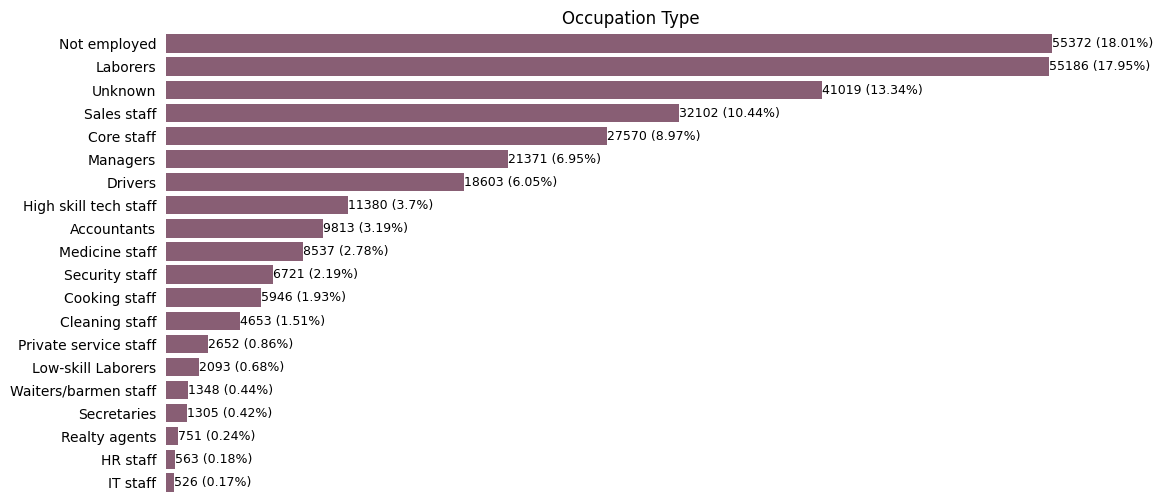

In [45]:
fig = plt.figure(figsize=(12, 6))

occ_t_counts = app_train['OCCUPATION_TYPE'].value_counts()

ax = bar_plot_f_perc_horizontal(occ_t_counts, 'Occupation Type', color='#8f5774')

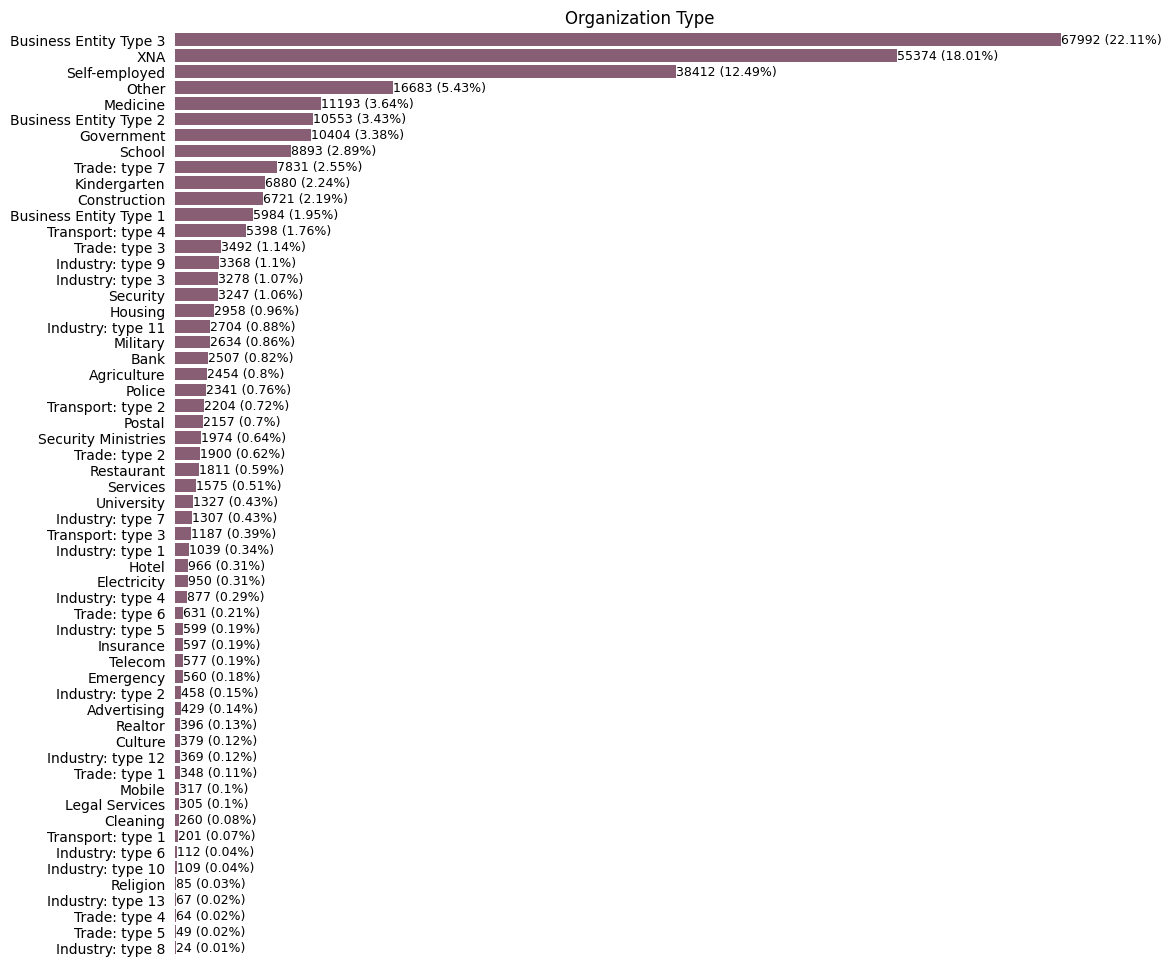

In [46]:
fig = plt.figure(figsize=(12, 12))

org_t_counts = app_train['ORGANIZATION_TYPE'].value_counts()

ax = bar_plot_f_perc_horizontal(org_t_counts, 'Organization Type', color='#8f5774')

We can see that both in occupation types and organization types there are rare categories. It might be good to combine them creating less categories.



In [47]:
features = cat_cols.copy()
features.remove('TARGET')

fig, axs = plt.subplots(len(features), 1, figsize=(14, (5.5 * len(features))))

palette = 'crest'

i = 0
for item in features:
    temp = app_train.groupby(item)['TARGET'].value_counts()

    title = item.replace("_", " ").title()

    mylist = ['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_HOUSING_TYPE']
    if item in mylist:
        ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, rotation=20, ax=axs[i])
    else:
        ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, ax=axs[i])
    ax.legend(edgecolor='none', title='Target')

    ind = temp.index
    if len(ind) == 4:
        ax.set_xticklabels(['No', 'Yes'])

    i += 1

We can see some tendencies which cause the client to have problems paying credits (target). For example, there are proportionaly more people who struggle with cash loans compared (8.35% of people with cash loans had target) to revolting loans (5.48%). There is also tendencies that males (10%) had the target more often compared to females (7%).

There were some categories in features which are very rare (for example, only 5 people on maternity leave, 18 students in NAME_INCOME_TYPE). Although this information would be valuable, there is too little data regarding these categories and therefore it would be good to combine some of these rare categories into one or remove them later on, during one hot encoding.

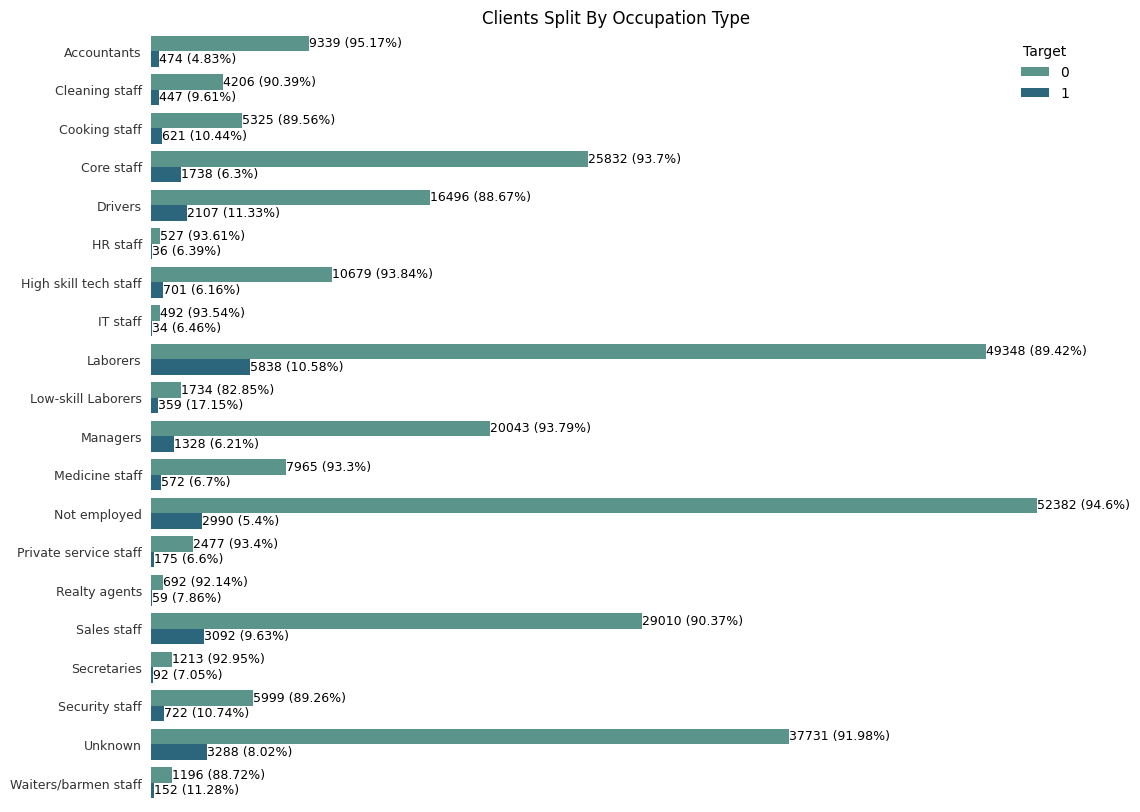

In [48]:
fig = plt.figure(figsize=(12, 10))

occ_c_target = app_train.groupby('OCCUPATION_TYPE')['TARGET'].value_counts()

ax = bar_plot_multi_index_f_horizontal(
    occ_c_target, 'OCCUPATION_TYPE', 'TARGET', 'Clients Split By Occupation Type', palette
)
ax.legend(edgecolor='none', title='Target');

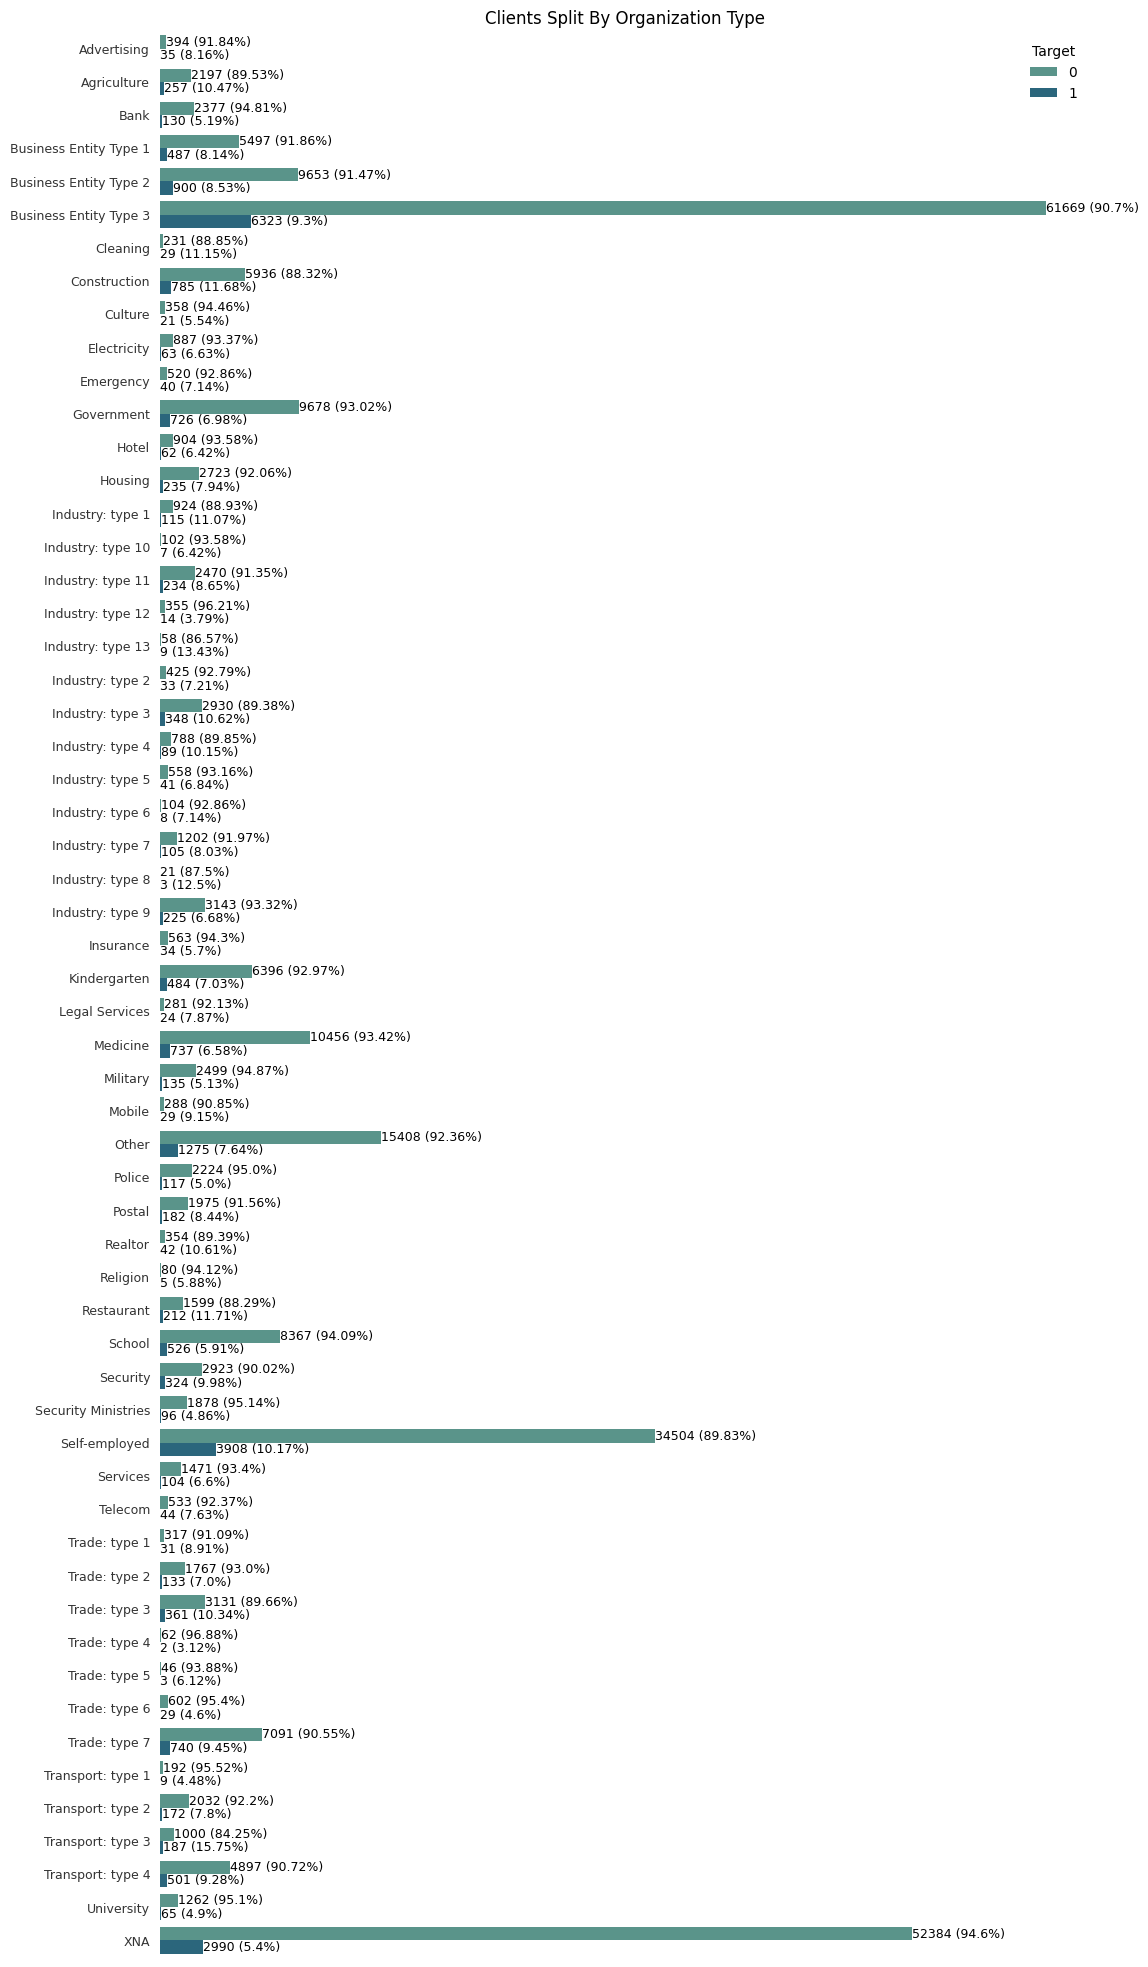

In [49]:
fig = plt.figure(figsize=(12, 25))

org_c_target = app_train.groupby('ORGANIZATION_TYPE')['TARGET'].value_counts()

ax = bar_plot_multi_index_f_horizontal(
    org_c_target, 'ORGANIZATION_TYPE', 'TARGET', 'Clients Split By Organization Type', palette
)
ax.legend(edgecolor='none', title='Target');

In occupation and organization types we can also see similar tendencies of some categories being rare. 

There are tendencies in occupation types that low skill laborers have highest percentage of target compared to others (17%). Also cooking staff, drivers, laborers security staff and waters/barmen have around 10%.

For organization type three categories with highest target percentages are transport: type 3, industry type 13 and restaurant.

### Numerical Features

In [50]:
num_feat_int = ['CNT_CHILDREN', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'HOUR_APPR_PROCESS_START']
num_feat_float = app_train.select_dtypes(include=['float']).columns

#### Integer Features

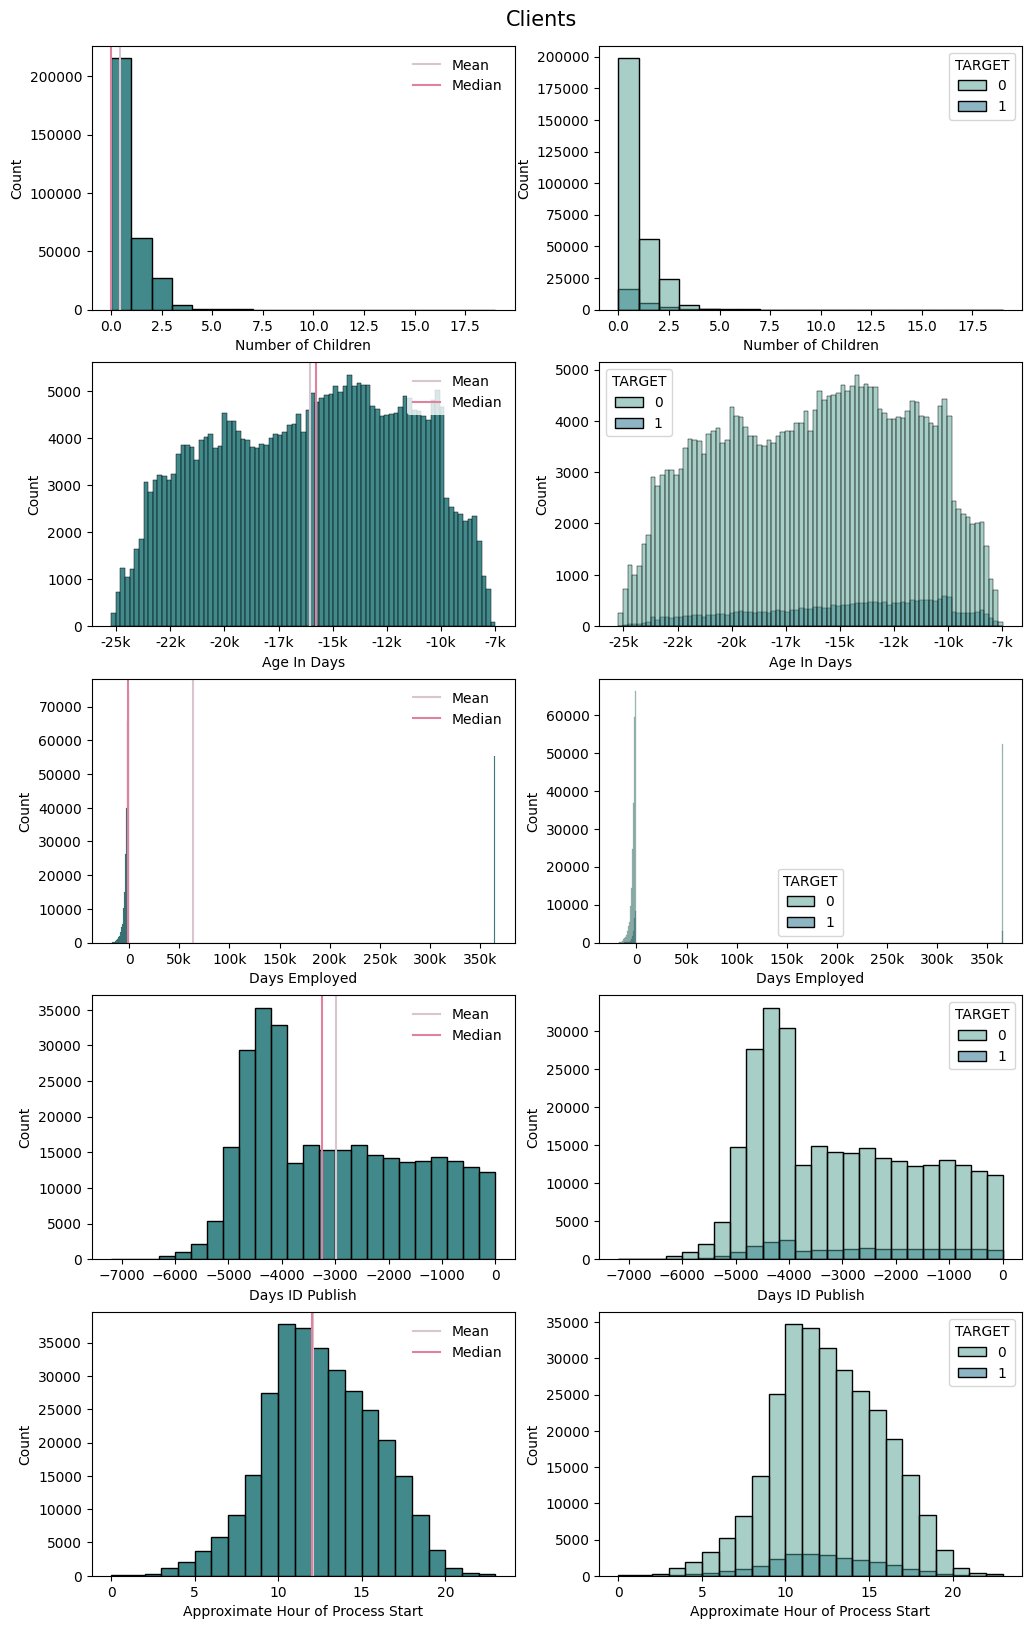

In [51]:
fig, axs = plt.subplots(5, 2, figsize=(12, 18))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.96)

ch = '#036264'
cmed = '#e0829d'
cmean = '#dac4d0'

ax00 = histplot_f(
    app_train.CNT_CHILDREN,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Number of Children',
    binwidth=1,
    ax=axs[0, 0],
)
ax01 = simple_histplot(
    app_train, 'CNT_CHILDREN', xlabel='Number of Children', hue='TARGET', palette=palette, binwidth=1, ax=axs[0, 1]
)

ax10 = histplot_f(
    app_train.DAYS_BIRTH, color=ch, color_median=cmed, color_mean=cmean, xlabel='Age In Days', ax=axs[1, 0]
)
ax10.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))

ax11 = simple_histplot(app_train, 'DAYS_BIRTH', xlabel='Age In Days', hue='TARGET', palette=palette, ax=axs[1, 1])
ax11.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))

ax20 = histplot_f(
    app_train.DAYS_EMPLOYED,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Days Employed',
    binwidth=1000,
    ax=axs[2, 0],
)
ax20.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax21 = simple_histplot(
    app_train, 'DAYS_EMPLOYED', xlabel='Days Employed', hue='TARGET', palette=palette, binwidth=1000, ax=axs[2, 1]
)
ax21.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))

ax30 = histplot_f(
    app_train.DAYS_ID_PUBLISH,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Days ID Publish',
    binwidth=300,
    ax=axs[3, 0],
)
ax31 = simple_histplot(
    app_train, 'DAYS_ID_PUBLISH', xlabel='Days ID Publish', hue='TARGET', binwidth=300, palette=palette, ax=axs[3, 1]
)

ax40 = histplot_f(
    app_train.HOUR_APPR_PROCESS_START,
    color=ch,
    color_median=cmed,
    color_mean=cmean,
    xlabel='Approximate Hour of Process Start',
    binwidth=1,
    ax=axs[4, 0],
)
ax41 = simple_histplot(
    app_train,
    'HOUR_APPR_PROCESS_START',
    xlabel='Approximate Hour of Process Start',
    hue='TARGET',
    binwidth=1,
    palette=palette,
    ax=axs[4, 1],
)

Number of children is highly skewed right. Age in days is distributed almost uniformaly across the spectrum with decreases at both ends. Days ID publish is skewed to the left, ha maximum at around -4500, and distributed uniformaly to the right. Approximate hour of process start has maximum at around 10, approximatelly normaly distributed and is slightly skewed to the left.

We can see some tendencies that older people are less likelly to have trouble repaying credit.  

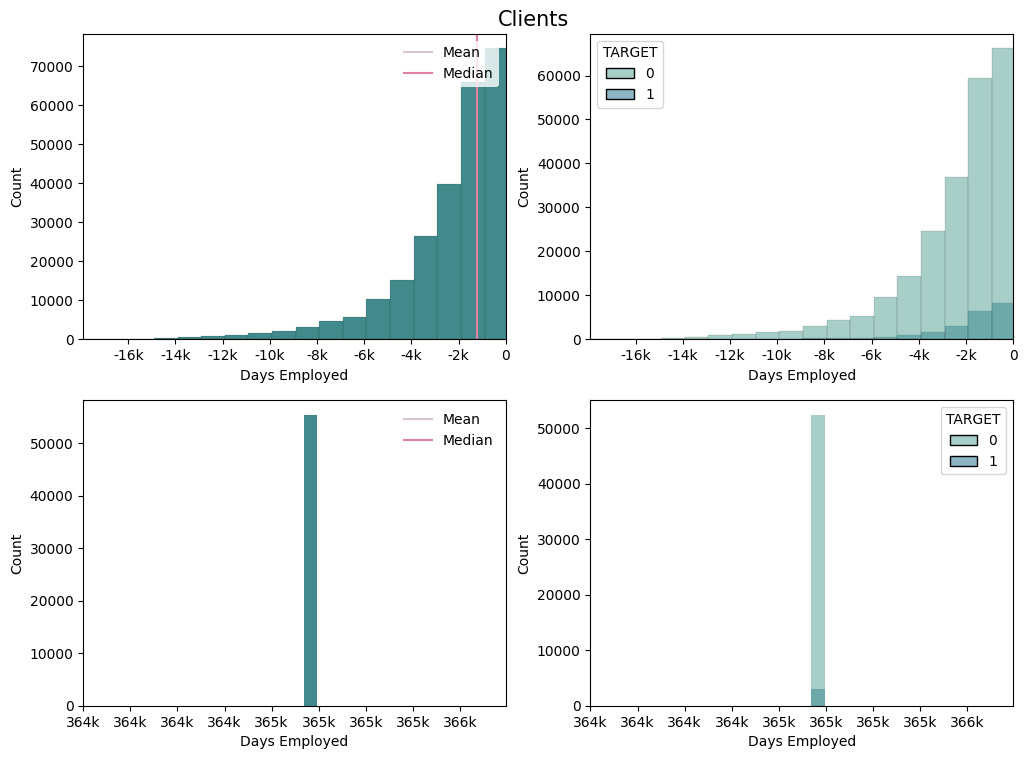

In [52]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.95)

ax00 = histplot_f(app_train.DAYS_EMPLOYED, color=ch, color_median=cmed, color_mean=cmean, binwidth=1000, ax=axs[0, 0])
lower_lim = app_train.DAYS_EMPLOYED.min()
ax00.set(xlabel='Days Employed', xlim=(lower_lim, 0))
ax00.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax01 = simple_histplot(
    app_train, 'DAYS_EMPLOYED', xlabel='Days Employed', hue='TARGET', palette=palette, binwidth=1000, ax=axs[0, 1]
)
ax01.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax01.set(xlim=(lower_lim, 0))

ax10 = histplot_f(app_train.DAYS_EMPLOYED, color=ch, color_median=cmed, color_mean=cmean, ax=axs[1, 0])
higher_lim = app_train.DAYS_EMPLOYED.max() + 1000
ax10.set(xlabel='Days Employed', xlim=(364000, higher_lim))
ax10.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax11 = simple_histplot(app_train, 'DAYS_EMPLOYED', xlabel='Days Employed', hue='TARGET', palette=palette, ax=axs[1, 1])
ax11.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax11.set(xlim=(364000, higher_lim));

In [53]:
sorted(app_train.DAYS_EMPLOYED.unique(), reverse=True)[:5]

[np.int64(365243), np.int64(0), np.int64(-1), np.int64(-2), np.int64(-3)]

DAYS_EMPLOYED represents the number of days a person has been employed, with negative values indicating how many days before the application they began employment. However, the value 365243 is used as a special flag to represent applicants who are not currently employed — it’s not a real duration.

#### From AMT Income Total to Ext Source 3

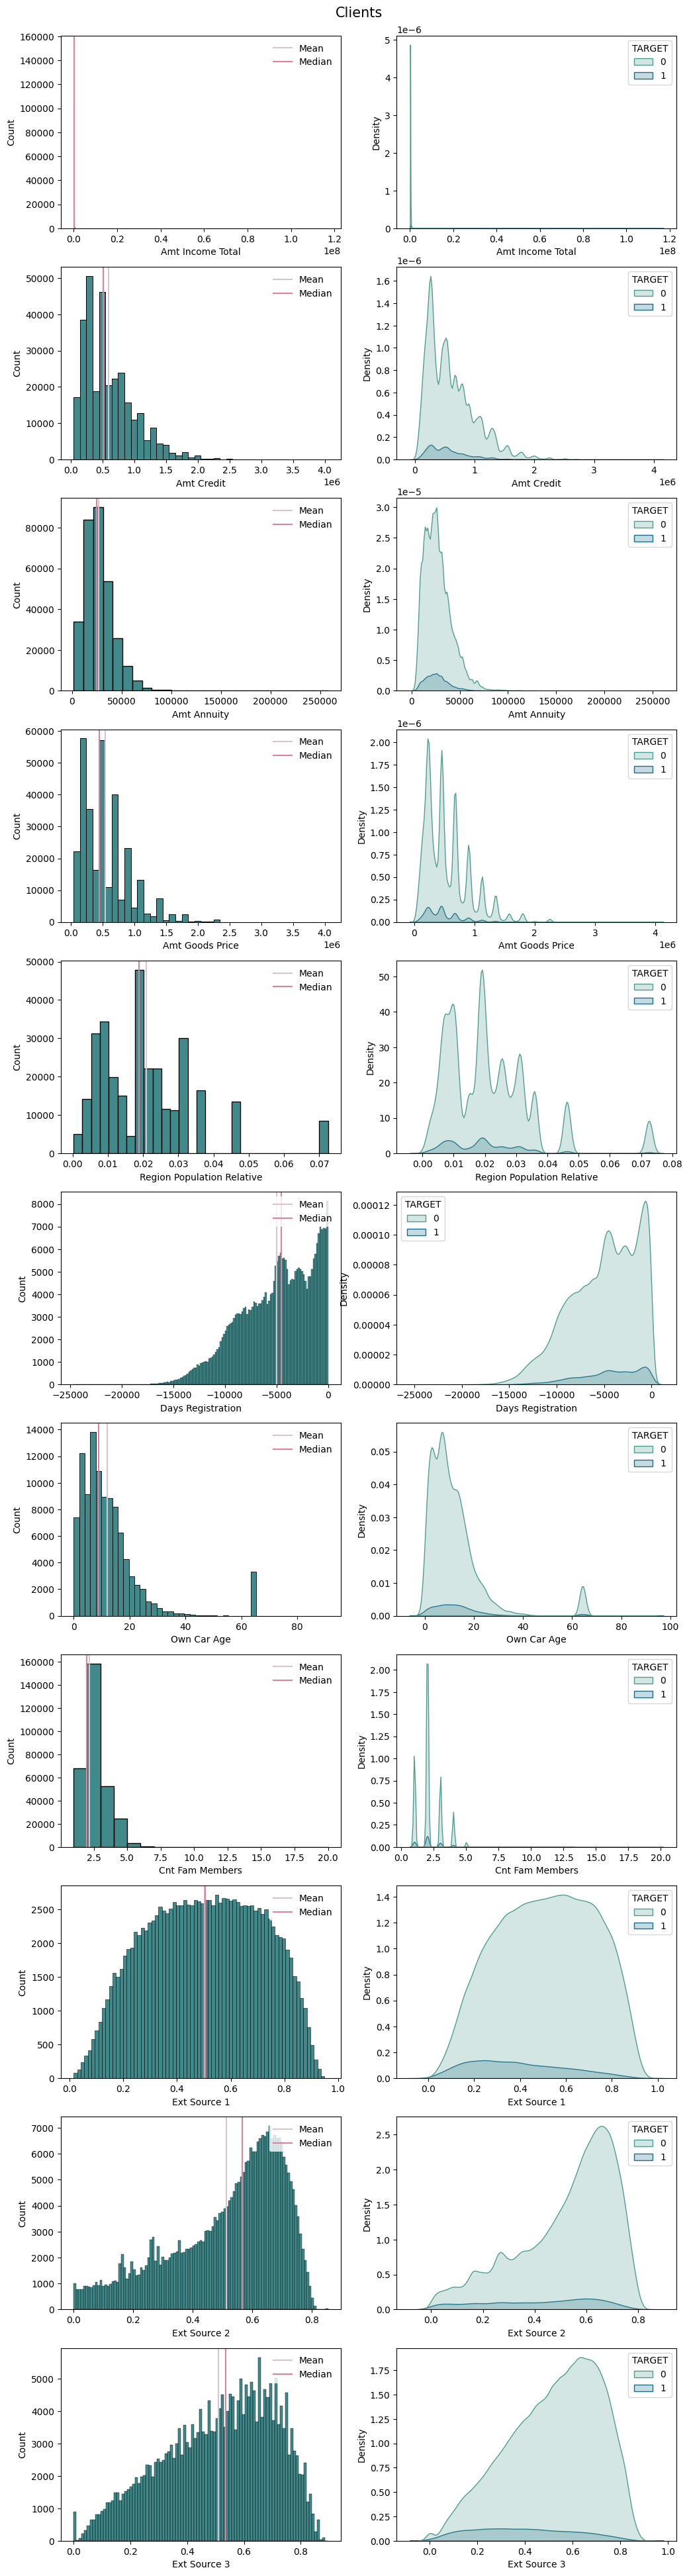

In [54]:
first_part = num_feat_float[0:11]
size = len(first_part)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.97)

i = 0
for item in first_part:
    if item in ['CNT_FAM_MEMBERS']:
        binw = 1
    elif item in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_GOODS_PRICE']:
        binw = 100000
    elif item in ['AMT_ANNUITY']:
        binw = 10000
    elif item in ['REGION_POPULATION_RELATIVE']:
        binw = 0.0025
    elif item in ['OWN_CAR_AGE']:
        binw = 2
    else:
        binw = None

    title = item.replace("_", " ").title()
    ax00 = histplot_f(
        app_train[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
    )
    ax01 = simple_kdeplot(app_train, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i, 1])

    i += 1

A lot of features are highly skewed (for example, Amt Credit is skewed to the right and days registration is skewed to the left).

There are some tendencies that with increase of other sources scores the probability of target decreased.

In [55]:
car_64_count = (app_train['OWN_CAR_AGE'] == 64).sum()
total_non_nan = app_train['OWN_CAR_AGE'].notna().sum()
percentage = (car_64_count / total_non_nan) * 100

print(f"{car_64_count} entries are 64 years old, which is {percentage:.2f}% of non-missing data.")

2443 entries are 64 years old, which is 2.34% of non-missing data.


There's an anomaly in the data - there is a spike of car age of 64 years old, which seems unlikelly. Therefore these values will be replaced with nan, as this age is likelly due to an error.

In [56]:
app_train['CAR_AGE_WAS_64'] = (app_train['OWN_CAR_AGE'] == 64).astype(int)
app_train['OWN_CAR_AGE'] = app_train['OWN_CAR_AGE'].replace(64, np.nan)

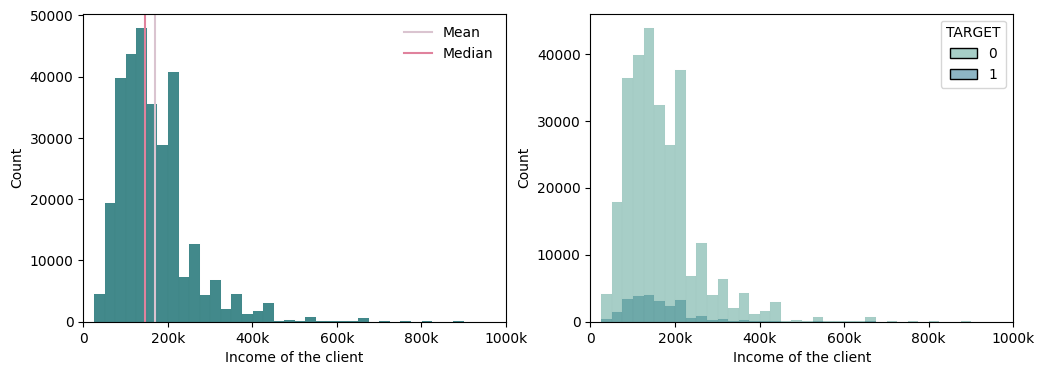

In [57]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax00 = histplot_f(app_train.AMT_INCOME_TOTAL, color=ch, color_median=cmed, color_mean=cmean, binwidth=25000, ax=axs[0])
ax00.set(xlabel='Income of the client', xlim=(0, 1000000))
ax00.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax01 = simple_histplot(
    app_train,
    'AMT_INCOME_TOTAL',
    xlabel='Income of the client',
    hue='TARGET',
    palette=palette,
    binwidth=25000,
    ax=axs[1],
)
ax01.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax01.set(xlim=(0, 1000000));

In [58]:
sorted(app_train.AMT_INCOME_TOTAL.unique(), reverse=True)[:5]

[np.float64(117000000.0),
 np.float64(18000090.0),
 np.float64(13500000.0),
 np.float64(9000000.0),
 np.float64(6750000.0)]

There's one extremelly high value for clients income. A billionaire coming to a credit institution is unlikelly - 117,000,000 is much larger than all other incomes — by an order of magnitude. Therefore the value will be replaced with median.

In [59]:
mask = app_train['AMT_INCOME_TOTAL'] < 2e7, 'AMT_INCOME_TOTAL'
realistic_median = app_train.loc[mask].median()

# Replace suspiciously high income with the realistic median
mask = app_train['AMT_INCOME_TOTAL'] > 2e7, 'AMT_INCOME_TOTAL'
app_train.loc[mask] = realistic_median

#### Building Features Average

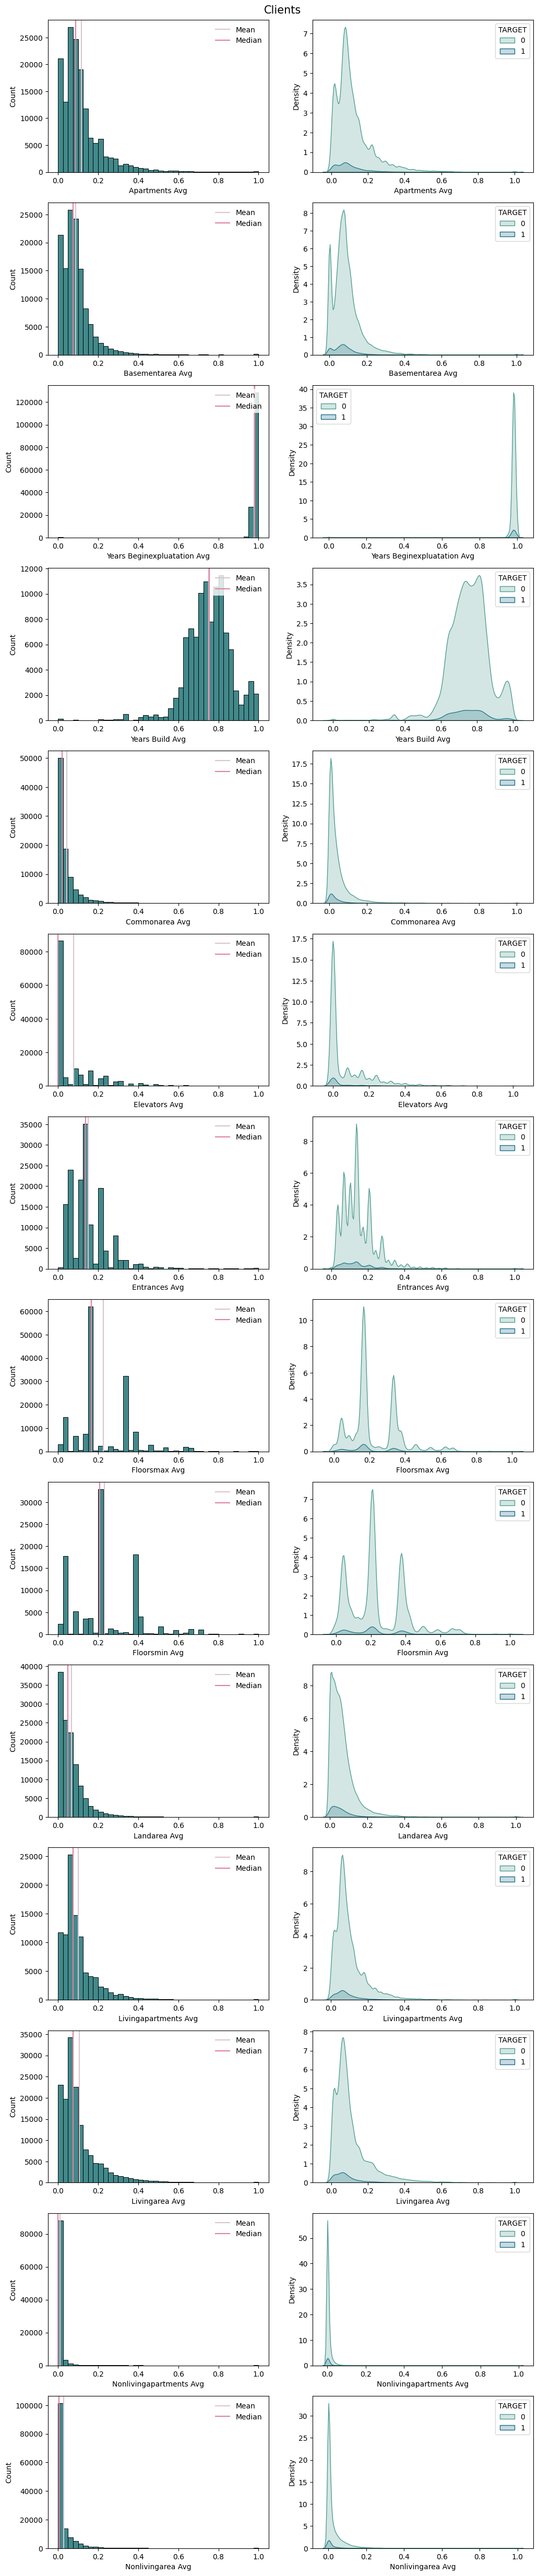

In [60]:
sec_part = num_feat_float[11:25]
size = len(sec_part)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.975)

i = 0
for item in sec_part:
    binw = 0.025

    title = item.replace("_", " ").title()
    ax00 = histplot_f(
        app_train[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
    )
    ax01 = simple_kdeplot(app_train, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i, 1])

    i += 1

Other than the data is highly skewed for most of parameters there are no clear tendencies we can see in relation to the target.

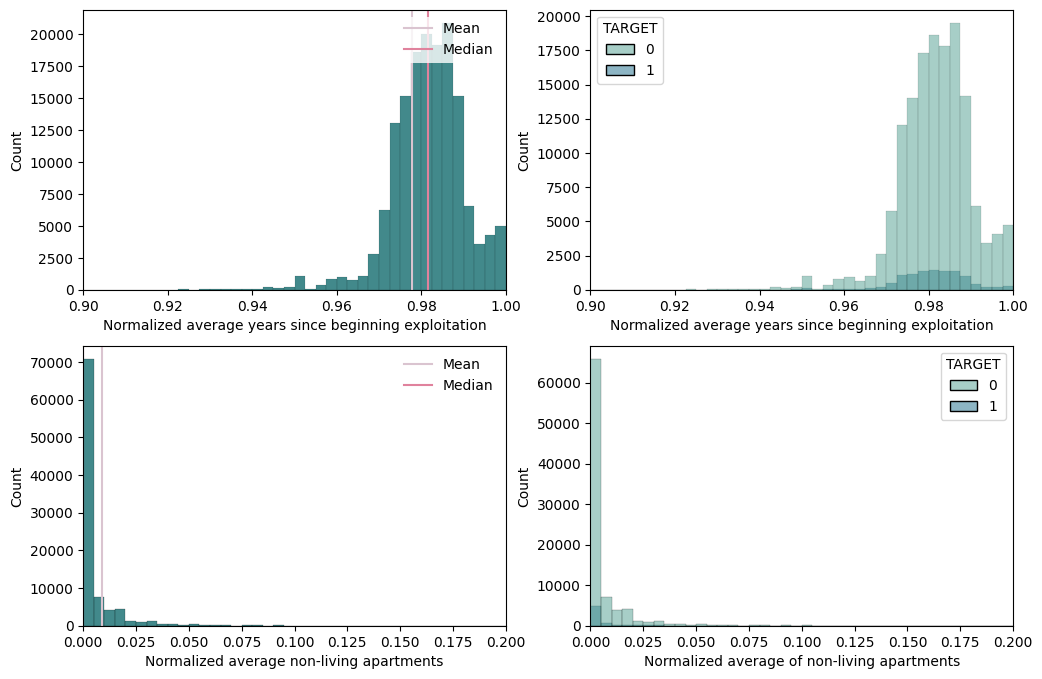

In [61]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

ax00 = histplot_f(
    app_train.YEARS_BEGINEXPLUATATION_AVG, color=ch, color_median=cmed, color_mean=cmean, binwidth=0.0025, ax=axs[0, 0]
)
ax00.set(xlabel='Normalized average years since beginning exploitation', xlim=(0.9, 1))
ax01 = simple_histplot(
    app_train,
    'YEARS_BEGINEXPLUATATION_AVG',
    xlabel='Normalized average years since beginning exploitation',
    hue='TARGET',
    palette=palette,
    binwidth=0.0025,
    ax=axs[0, 1],
)
ax01.set(xlim=(0.9, 1))

ax00 = histplot_f(
    app_train.NONLIVINGAPARTMENTS_AVG, color=ch, color_median=cmed, color_mean=cmean, binwidth=0.005, ax=axs[1, 0]
)
ax00.set(xlabel='Normalized average non-living apartments', xlim=(0, 0.2))
ax01 = simple_histplot(
    app_train,
    'NONLIVINGAPARTMENTS_AVG',
    xlabel='Normalized average of non-living apartments',
    hue='TARGET',
    palette=palette,
    binwidth=0.005,
    ax=axs[1, 1],
)
ax01.set(xlim=(0, 0.2));

There are some tendensies that the more years the building was exploited, the less troubles with repaying the credit. Majority of the buildings didn't have non-living apartments or very little of them.

#### Building Features Mode

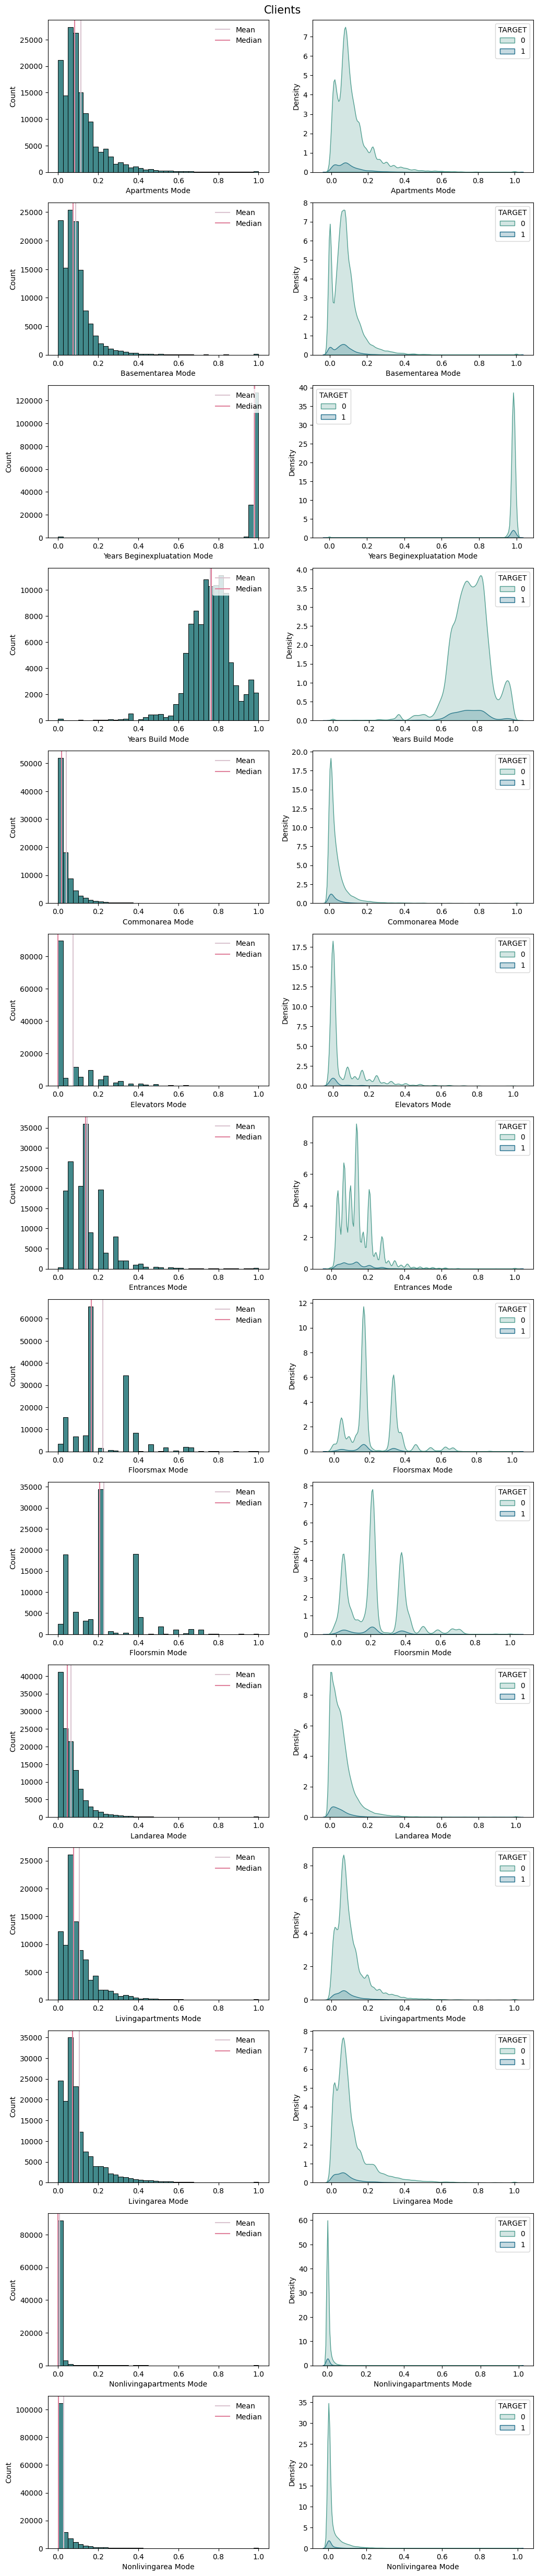

In [62]:
third_part = num_feat_float[25:39]
size = len(third_part)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.975)

i = 0
for item in third_part:
    binw = 0.025

    title = item.replace("_", " ").title()
    ax00 = histplot_f(
        app_train[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
    )
    ax01 = simple_kdeplot(app_train, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i, 1])

    i += 1

Distributions are highly similar to corresponding averages

#### Building Features Median

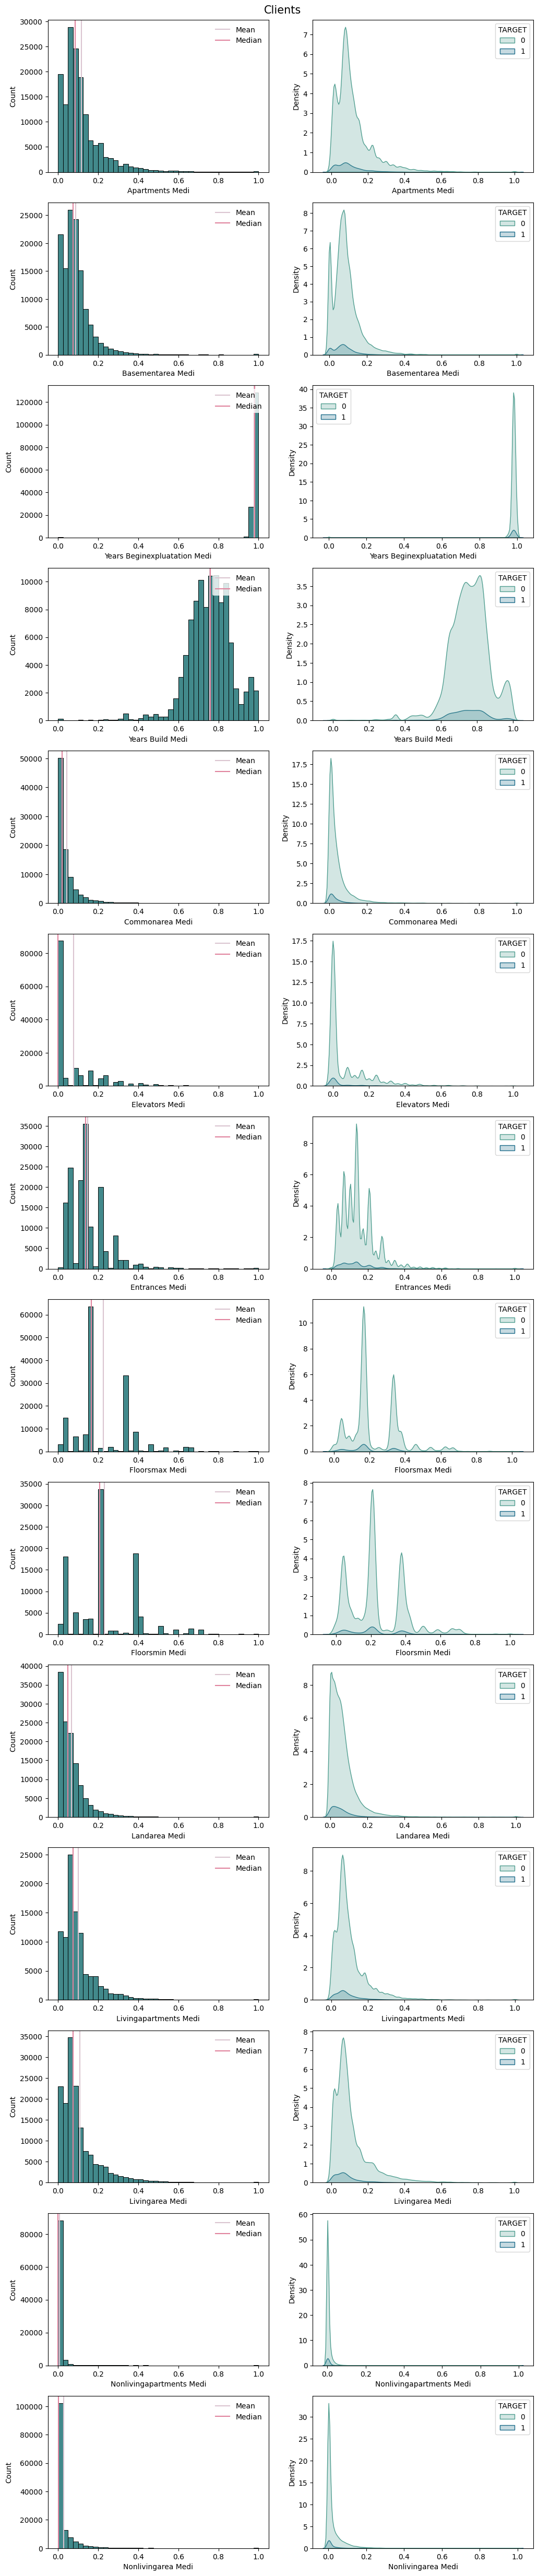

In [63]:
fourth_part = num_feat_float[39:53]
size = len(fourth_part)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.975)

i = 0
for item in fourth_part:
    binw = 0.025

    title = item.replace("_", " ").title()
    ax00 = histplot_f(
        app_train[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
    )
    ax01 = simple_kdeplot(app_train, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i, 1])

    i += 1

Distributions are highly similar to both corresponding averages and modes.

#### From Total Area Mode to the End

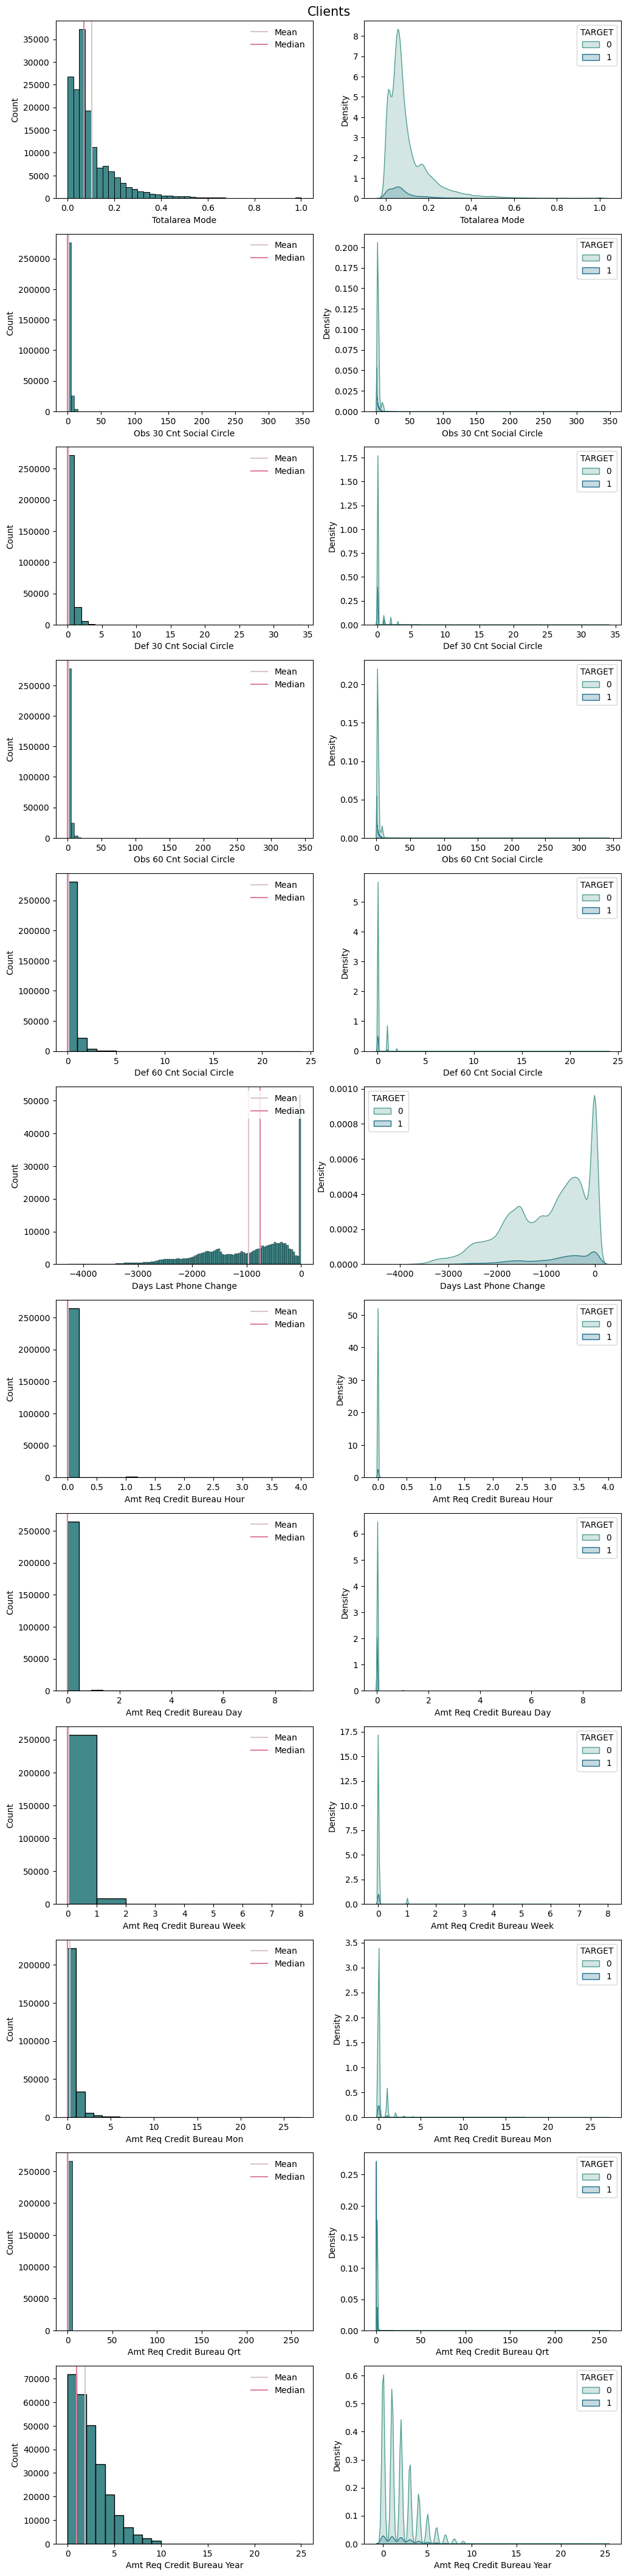

In [64]:
fifth_part = num_feat_float[53:]
size = len(fifth_part)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

fig.suptitle('Clients', fontsize=15)
fig.subplots_adjust(top=0.975)

i = 0
for item in fifth_part:
    if item in ['TOTALAREA_MODE']:
        binw = 0.025
    elif item in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_GOODS_PRICE']:
        binw = 100000
    elif item in ['AMT_ANNUITY']:
        binw = 10000
    elif item in ['AMT_REQ_CREDIT_BUREAU_QRT', 'OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE']:
        binw = 5
    elif item in [
        'AMT_REQ_CREDIT_BUREAU_YEAR',
        'AMT_REQ_CREDIT_BUREAU_MON',
        'AMT_REQ_CREDIT_BUREAU_WEEK',
        'DEF_60_CNT_SOCIAL_CIRCLE',
        'DEF_30_CNT_SOCIAL_CIRCLE',
    ]:
        binw = 1
    else:
        binw = None

    title = item.replace("_", " ").title()
    ax00 = histplot_f(
        app_train[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
    )
    ax01 = simple_kdeplot(app_train, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i, 1])

    i += 1

All of the features are highly skewed to the right, except for DAYS_LAST_PHONE_CHANGE which is skewed to the left. There are many clients which had 0 for DAYS_LAST_PHONE_CHANGE, which is most likely a holder value for missing this information.

#### Extreme Values in Social Circle

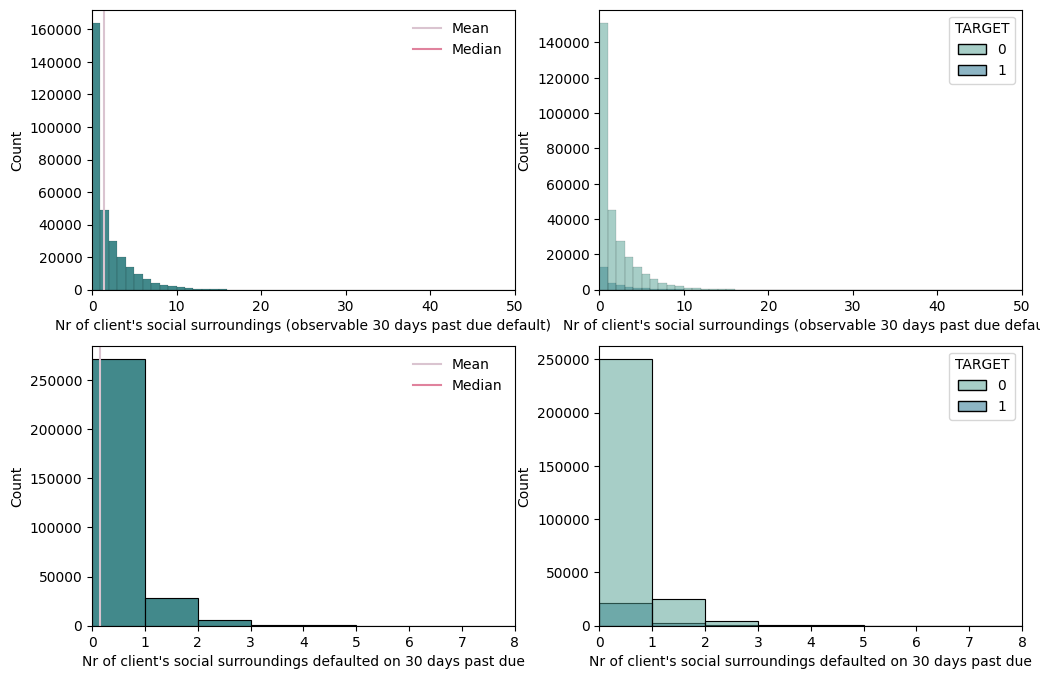

In [65]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

ax00 = histplot_f(
    app_train.OBS_30_CNT_SOCIAL_CIRCLE, color=ch, color_median=cmed, color_mean=cmean, binwidth=1, ax=axs[0, 0]
)
ax00.set(xlabel="Nr of client's social surroundings (observable 30 days past due default)", xlim=(0, 50))
ax01 = simple_histplot(
    app_train,
    'OBS_30_CNT_SOCIAL_CIRCLE',
    xlabel="Nr of client's social surroundings (observable 30 days past due default)",
    hue='TARGET',
    palette=palette,
    binwidth=1,
    ax=axs[0, 1],
)
ax01.set(xlim=(0, 50))

ax00 = histplot_f(
    app_train.DEF_30_CNT_SOCIAL_CIRCLE, color=ch, color_median=cmed, color_mean=cmean, binwidth=1, ax=axs[1, 0]
)
ax00.set(xlabel="Nr of client's social surroundings defaulted on 30 days past due", xlim=(0, 8))
ax01 = simple_histplot(
    app_train,
    'DEF_30_CNT_SOCIAL_CIRCLE',
    xlabel="Nr of client's social surroundings defaulted on 30 days past due",
    hue='TARGET',
    palette=palette,
    binwidth=1,
    ax=axs[1, 1],
)
ax01.set(xlim=(0, 8));

In [66]:
app_train.OBS_30_CNT_SOCIAL_CIRCLE.value_counts().iloc[-6:]

OBS_30_CNT_SOCIAL_CIRCLE
26.0     3
30.0     2
29.0     1
28.0     1
47.0     1
348.0    1
Name: count, dtype: int64

In [67]:
app_train.DEF_30_CNT_SOCIAL_CIRCLE.value_counts().iloc[-6:]

DEF_30_CNT_SOCIAL_CIRCLE
4.0     253
5.0      56
6.0      11
7.0       1
34.0      1
8.0       1
Name: count, dtype: int64

Values 348 and 47 for OBS_30_CNT_SOCIAL_CIRCLE and 34 for DEF_30_CNT_SOCIAL_CIRCLE seems to extreme and therefore will be replaced with median.

In [68]:
realistic_median_obs_30 = app_train.loc[app_train['OBS_30_CNT_SOCIAL_CIRCLE'] < 31, 'OBS_30_CNT_SOCIAL_CIRCLE'].median()
realistic_median_def_30 = app_train.loc[app_train['DEF_30_CNT_SOCIAL_CIRCLE'] < 10, 'DEF_30_CNT_SOCIAL_CIRCLE'].median()

# Replace values with the median
app_train.loc[app_train['OBS_30_CNT_SOCIAL_CIRCLE'] >= 31, 'OBS_30_CNT_SOCIAL_CIRCLE'] = realistic_median_obs_30
app_train.loc[app_train['DEF_30_CNT_SOCIAL_CIRCLE'] >= 10, 'DEF_30_CNT_SOCIAL_CIRCLE'] = realistic_median_def_30

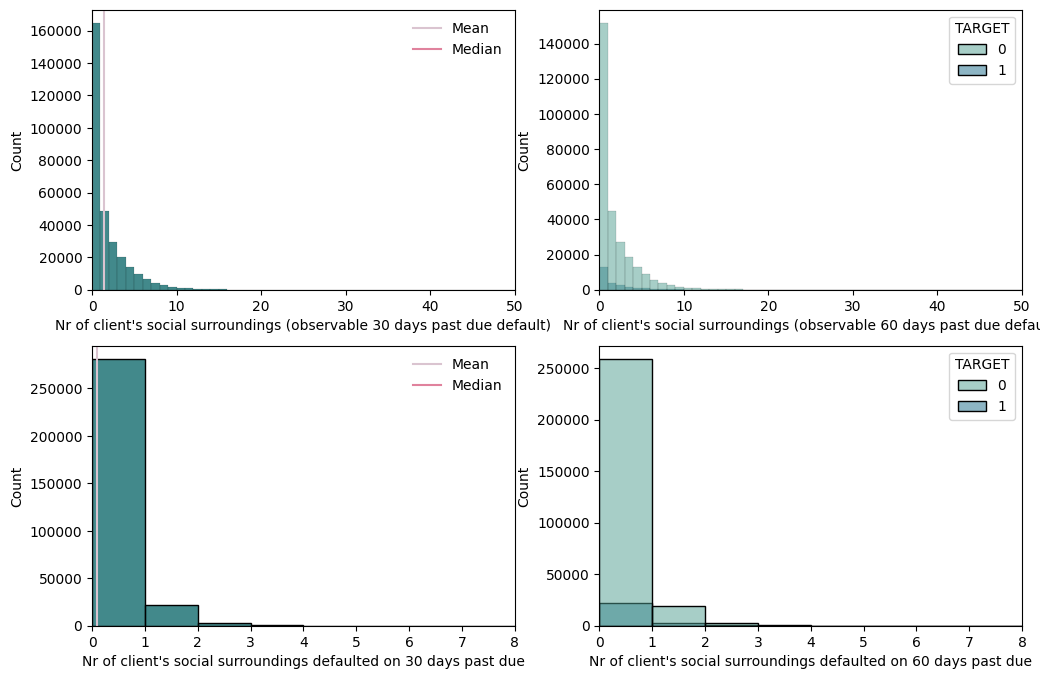

In [69]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

ax00 = histplot_f(
    app_train.OBS_60_CNT_SOCIAL_CIRCLE, color=ch, color_median=cmed, color_mean=cmean, binwidth=1, ax=axs[0, 0]
)
ax00.set(xlabel="Nr of client's social surroundings (observable 30 days past due default)", xlim=(0, 50))
ax01 = simple_histplot(
    app_train,
    'OBS_60_CNT_SOCIAL_CIRCLE',
    xlabel="Nr of client's social surroundings (observable 60 days past due default)",
    hue='TARGET',
    palette=palette,
    binwidth=1,
    ax=axs[0, 1],
)
ax01.set(xlim=(0, 50))

ax00 = histplot_f(
    app_train.DEF_60_CNT_SOCIAL_CIRCLE, color=ch, color_median=cmed, color_mean=cmean, binwidth=1, ax=axs[1, 0]
)
ax00.set(xlabel="Nr of client's social surroundings defaulted on 30 days past due", xlim=(0, 8))
ax01 = simple_histplot(
    app_train,
    'DEF_60_CNT_SOCIAL_CIRCLE',
    xlabel="Nr of client's social surroundings defaulted on 60 days past due",
    hue='TARGET',
    palette=palette,
    binwidth=1,
    ax=axs[1, 1],
)
ax01.set(xlim=(0, 8));

In [70]:
app_train.OBS_60_CNT_SOCIAL_CIRCLE.value_counts().iloc[-6:]

OBS_60_CNT_SOCIAL_CIRCLE
29.0     2
28.0     1
47.0     1
344.0    1
30.0     1
26.0     1
Name: count, dtype: int64

In [71]:
app_train.DEF_60_CNT_SOCIAL_CIRCLE.value_counts().iloc[-6:]

DEF_60_CNT_SOCIAL_CIRCLE
3.0     598
4.0     135
5.0      20
6.0       3
7.0       1
24.0      1
Name: count, dtype: int64

Again there seems to be some rare extreme values, like 344 and 47 for OBS_60_CNT_SOCIAL_CIRCLE and 24 for DEF_60_CNT_SOCIAL_CIRCLE and they will be replaced with median.

In [72]:
realistic_median_obs_60 = app_train.loc[app_train['OBS_60_CNT_SOCIAL_CIRCLE'] < 31, 'OBS_60_CNT_SOCIAL_CIRCLE'].median()
realistic_median_def_60 = app_train.loc[app_train['DEF_60_CNT_SOCIAL_CIRCLE'] < 10, 'DEF_60_CNT_SOCIAL_CIRCLE'].median()

# Replace values with the median
app_train.loc[app_train['OBS_60_CNT_SOCIAL_CIRCLE'] >= 31, 'OBS_60_CNT_SOCIAL_CIRCLE'] = realistic_median_obs_60
app_train.loc[app_train['DEF_60_CNT_SOCIAL_CIRCLE'] >= 10, 'DEF_60_CNT_SOCIAL_CIRCLE'] = realistic_median_def_60

#### 0 in DAYS_LAST_PHONE_CHANGE

There are a lot of 0 values in DAYS_LAST_PHONE_CHANGE indicating that it is missing values or placehoder data. 

In [73]:
app_train.groupby(app_train['DAYS_LAST_PHONE_CHANGE'] == 0)['TARGET'].mean()

DAYS_LAST_PHONE_CHANGE
False    0.078506
True     0.096650
Name: TARGET, dtype: float64

This shows that applicants with DAYS_LAST_PHONE_CHANGE == 0 have a noticeably higher default rate (≈9.7%) compared to those with non-zero values (≈7.9%). Therefore it is worth creating a feature indicating this. Few nan values will also be included in it. Also 0 values will be replaced with nan:

In [74]:
app_train['DAYS_LAST_PHONE_CHANGE'] = app_train['DAYS_LAST_PHONE_CHANGE'].replace(0, np.nan)
app_train['PHONE_CHANGE_SUS_FLAG'] = (app_train['DAYS_LAST_PHONE_CHANGE'].isna()).astype(int)

#### Extreme Value in Credit Bureau

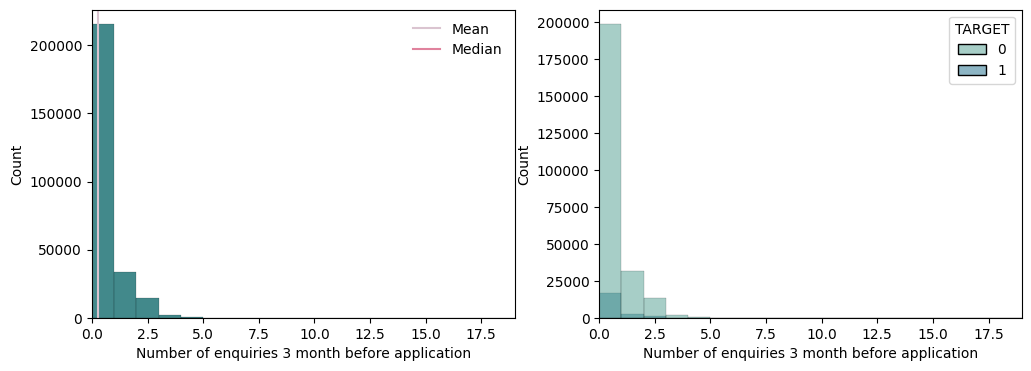

In [75]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax00 = histplot_f(
    app_train.AMT_REQ_CREDIT_BUREAU_QRT, color=ch, color_median=cmed, color_mean=cmean, binwidth=1, ax=axs[0]
)
ax00.set(xlabel='Number of enquiries 3 month before application', xlim=(0, 19))
ax01 = simple_histplot(
    app_train,
    'AMT_REQ_CREDIT_BUREAU_QRT',
    xlabel='Number of enquiries 3 month before application',
    hue='TARGET',
    palette=palette,
    binwidth=1,
    ax=axs[1],
)
ax01.set(xlim=(0, 19));

In [76]:
app_train.AMT_REQ_CREDIT_BUREAU_HOUR.value_counts()

AMT_REQ_CREDIT_BUREAU_HOUR
0.0    264366
1.0      1560
2.0        56
3.0         9
4.0         1
Name: count, dtype: int64

In [77]:
app_train.AMT_REQ_CREDIT_BUREAU_DAY.value_counts()

AMT_REQ_CREDIT_BUREAU_DAY
0.0    264503
1.0      1292
2.0       106
3.0        45
4.0        26
5.0         9
6.0         8
9.0         2
8.0         1
Name: count, dtype: int64

In [78]:
app_train.AMT_REQ_CREDIT_BUREAU_WEEK.value_counts()

AMT_REQ_CREDIT_BUREAU_WEEK
0.0    257456
1.0      8208
2.0       199
3.0        58
4.0        34
6.0        20
5.0        10
8.0         5
7.0         2
Name: count, dtype: int64

In [79]:
app_train.AMT_REQ_CREDIT_BUREAU_QRT.value_counts().iloc[-6:]

AMT_REQ_CREDIT_BUREAU_QRT
5.0      64
6.0      28
8.0       7
7.0       7
261.0     1
19.0      1
Name: count, dtype: int64

There seems to be one extreme value for AMT_REQ_CREDIT_BUREAU_QRT - 261, which will be replaced with median.

In [80]:
realistic_median_amt_req = app_train.loc[
    app_train['AMT_REQ_CREDIT_BUREAU_QRT'] < 20, 'OBS_60_CNT_SOCIAL_CIRCLE'
].median()

# Replace value with the median
app_train.loc[app_train['AMT_REQ_CREDIT_BUREAU_QRT'] >= 20, 'AMT_REQ_CREDIT_BUREAU_QRT'] = realistic_median_amt_req

### Feature Engineering and Removing

In [81]:
for col in ['EXT_SOURCE_1', 'EXT_SOURCE_3']:
    app_train[f'{col}_MISSING'] = app_train[col].isnull().astype(int)

In [82]:
app_train['MISSING_BUREAU_REQ'] = app_train['AMT_REQ_CREDIT_BUREAU_QRT'].isnull().astype(int)
app_train['BUILDING_MISSING_COUNT'] = app_train[building_avg].isna().sum(axis=1)
app_train['BUILDING_ALL_MISSING'] = (app_train['BUILDING_MISSING_COUNT'] == len(building_avg)).astype(int)
app_train['BUILDING_ANY_MISSING'] = (app_train['BUILDING_MISSING_COUNT'] >= 1).astype(int)
app_train['BUILDING_OTHER_MISSING_COUNT'] = app_train[building_other].isna().sum(axis=1)
app_train['BUILDING_OTHER_ALL_MISSING'] = (app_train['BUILDING_OTHER_MISSING_COUNT'] == len(building_other)).astype(int)
app_train['BUILDING_OTHER_ANY_MISSING'] = (app_train['BUILDING_OTHER_MISSING_COUNT'] >= 1).astype(int)

In [83]:
# Select all FLAG_DOCUMENT_* columns
flag_doc_cols = [col for col in app_train.columns if col.startswith('FLAG_DOCUMENT_')]

# Create a new column that is 1 if any document flag is 1, else 0
app_train['ANY_DOCUMENT_PRESENTED'] = app_train[flag_doc_cols].any(axis=1).astype(int)
app_train['DOCUMENTS_COUNT'] = app_train[flag_doc_cols].sum(axis=1)

In [84]:
app_train['CREDIT_INCOME_RATIO'] = app_train['AMT_CREDIT'] / app_train['AMT_INCOME_TOTAL']
app_train['ANNUITY_INCOME_RATIO'] = app_train['AMT_ANNUITY'] / app_train['AMT_INCOME_TOTAL']
app_train['ANNUITY_CREDIT_RATIO'] = app_train['AMT_ANNUITY'] / app_train['AMT_CREDIT']
app_train['GOODS_CREDIT_RATIO'] = app_train['AMT_GOODS_PRICE'] / app_train['AMT_CREDIT']

In [85]:
app_train['AGE_YEARS'] = (-app_train['DAYS_BIRTH']) // 365
app_train['YEARS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].apply(lambda x: x if x < 0 else np.nan) / -365
app_train['RECENT_PHONE_CHANGE'] = (app_train['DAYS_LAST_PHONE_CHANGE'] > -365).astype(int)

In [86]:
app_train['NAME_TYPE_SUITE_OTHER'] = (
    app_train['NAME_TYPE_SUITE'].isin(['Other_A', 'Other_B', 'Group of people']).astype(int)
)

app_train['NAME_EDUCATION_TYPE_SECONDARY'] = (
    app_train['NAME_EDUCATION_TYPE'].isin(['Secondary / secondary special', 'Lower secondary']).astype(int)
)

app_train['WALLSMATERIAL_MODE_UNCOMMON'] = (
    app_train['WALLSMATERIAL_MODE'].isin(['Block', 'Mixed', 'Wooden', 'Others', 'Monolithic']).astype(int)
)

In [87]:
occupation_map = {
    'Laborers': 'Manual',
    'Low-skill Laborers': 'Manual',
    'Drivers': 'Manual',
    'Cleaning staff': 'Manual',
    'Cooking staff': 'Manual',
    'Security staff': 'Manual',
    'Core staff': 'Office',
    'Secretaries': 'Office',
    'HR staff': 'Office',
    'Accountants': 'Professional',
    'Managers': 'Professional',
    'IT staff': 'Professional',
    'High skill tech staff': 'Professional',
    'Medicine staff': 'Professional',
    'Sales staff': 'Service',
    'Waiters/barmen staff': 'Service',
    'Private service staff': 'Service',
    'Realty agents': 'Service',
    'Not employed': 'Unemployed',
    'Unknown': 'Unemployed',
}

app_train['OCCUPATION_TYPE_GROUPED'] = app_train['OCCUPATION_TYPE'].map(occupation_map)

In [88]:
app_train['ORGANIZATION_TYPE_TRADE'] = app_train['ORGANIZATION_TYPE'].str.contains('Trade', case=False).astype(int)
app_train['ORGANIZATION_TYPE_INDUSTRY'] = (
    app_train['ORGANIZATION_TYPE'].str.contains('Industry', case=False).astype(int)
)
app_train['ORGANIZATION_TYPE_TRANSPORT'] = (
    app_train['ORGANIZATION_TYPE'].str.contains('Transport', case=False).astype(int)
)
app_train['ORGANIZATION_TYPE_BUSINESS_ENTITY'] = (
    app_train['ORGANIZATION_TYPE'].str.contains('Business Entity Type', case=False).astype(int)
)
app_train['ORGANIZATION_TYPE_GOVERNMENT'] = (
    app_train['ORGANIZATION_TYPE']
    .isin(['Government', 'Military', 'Police', 'Emergency', 'Security Ministries', 'Postal'])
    .astype(int)
)
app_train['ORGANIZATION_TYPE_EDUCATION'] = (
    app_train['ORGANIZATION_TYPE'].isin(['School', 'University', 'Kindergarten']).astype(int)
)
app_train['ORGANIZATION_TYPE_INFRASTRUCTURE'] = (
    app_train['ORGANIZATION_TYPE'].isin(['Construction', 'Housing', 'Electricity']).astype(int)
)
app_train['ORGANIZATION_TYPE_SERVICES'] = (
    app_train['ORGANIZATION_TYPE']
    .isin(['Self-employed', 'Services', 'Cleaning', 'Legal Services', 'Realtor', 'Security', 'Religion'])
    .astype(int)
)
app_train['ORGANIZATION_TYPE_FINANCE'] = app_train['ORGANIZATION_TYPE'].isin(['Bank', 'Insurance']).astype(int)
app_train['ORGANIZATION_TYPE_TECH'] = (
    app_train['ORGANIZATION_TYPE'].isin(['Telecom', 'Mobile', 'Advertising']).astype(int)
)
app_train['ORGANIZATION_TYPE_HOSPITALITY'] = (
    app_train['ORGANIZATION_TYPE'].isin(['Restaurant', 'Hotel', 'Culture']).astype(int)
)

In [89]:
app_train.columns[80:120]

Index(['FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI',
       'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI',
       'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'TOTALAREA_MODE',
       'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE', 'OBS_30_CNT_SOCIAL_CIRCLE',
       'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE',
       'DEF_60_CNT_SOCIAL_CIRCLE', 'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_2',
       'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5',
       'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_8',
       'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11',
       'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14',
       'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17',
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON'],
      dtype='o

In [90]:
columns_to_drop = [
    'FLAG_MOBIL',
    'FLAG_DOCUMENT_2',
    'FLAG_DOCUMENT_4',
    'FLAG_DOCUMENT_7',
    'FLAG_DOCUMENT_10',
    'FLAG_DOCUMENT_12',
    'FLAG_DOCUMENT_21',
]
app_train = app_train.drop(columns_to_drop, axis=1)

#### Created Features Charts

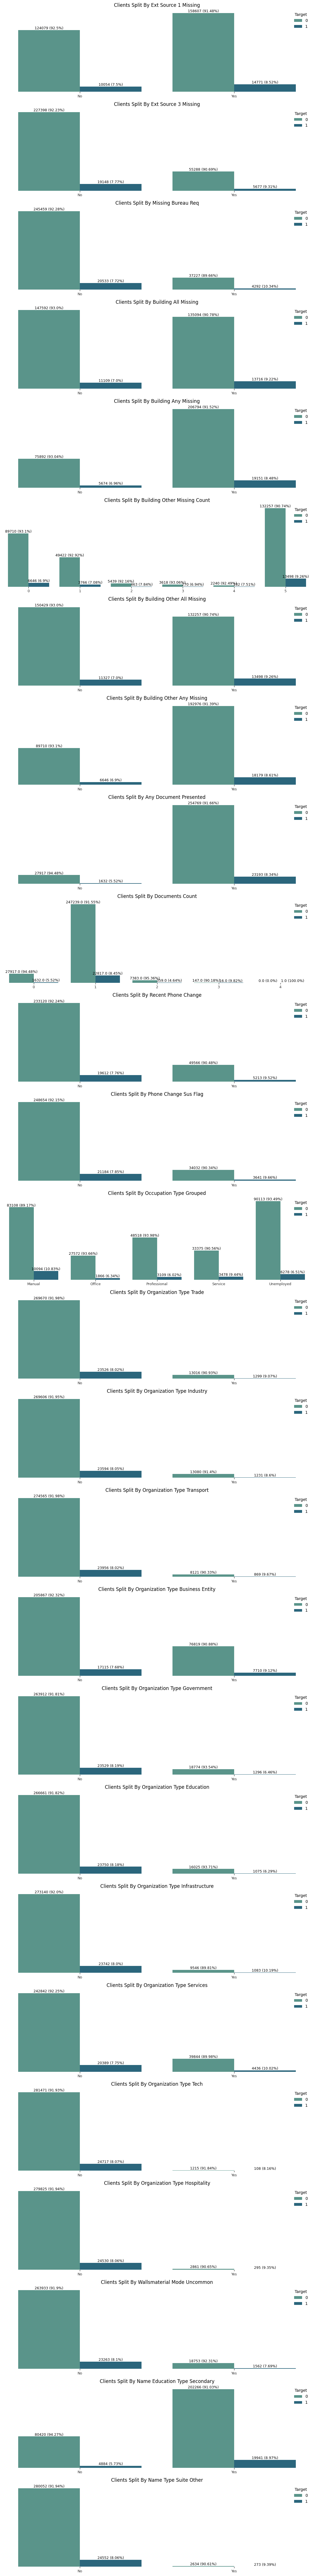

In [91]:
features = [
    'EXT_SOURCE_1_MISSING',
    'EXT_SOURCE_3_MISSING',
    'MISSING_BUREAU_REQ',
    'BUILDING_ALL_MISSING',
    'BUILDING_ANY_MISSING',
    'BUILDING_OTHER_MISSING_COUNT',
    'BUILDING_OTHER_ALL_MISSING',
    'BUILDING_OTHER_ANY_MISSING',
    'ANY_DOCUMENT_PRESENTED',
    'DOCUMENTS_COUNT',
    'RECENT_PHONE_CHANGE',
    'PHONE_CHANGE_SUS_FLAG',
    'OCCUPATION_TYPE_GROUPED',
    'ORGANIZATION_TYPE_TRADE',
    'ORGANIZATION_TYPE_INDUSTRY',
    'ORGANIZATION_TYPE_TRANSPORT',
    'ORGANIZATION_TYPE_BUSINESS_ENTITY',
    'ORGANIZATION_TYPE_GOVERNMENT',
    'ORGANIZATION_TYPE_EDUCATION',
    'ORGANIZATION_TYPE_INFRASTRUCTURE',
    'ORGANIZATION_TYPE_SERVICES',
    'ORGANIZATION_TYPE_TECH',
    'ORGANIZATION_TYPE_HOSPITALITY',
    'WALLSMATERIAL_MODE_UNCOMMON',
    'NAME_EDUCATION_TYPE_SECONDARY',
    'NAME_TYPE_SUITE_OTHER',
]

fig, axs = plt.subplots(len(features), 1, figsize=(14, (4.5 * len(features))))

i = 0
for item in features:
    temp = app_train.groupby(item)['TARGET'].value_counts()

    title = item.replace("_", " ").title()

    ax = bar_plot_multi_index_f(temp, item, 'TARGET', f'Clients Split By {title}', palette, ax=axs[i])
    ax.legend(edgecolor='none', title='Target')

    ind = temp.index
    if len(ind) == 4:
        ax.set_xticklabels(['No', 'Yes'])

    i += 1

In created features, there are also see some tendencies which cause the client to have problems paying credits (target). For example, having MISSING_BUREAU_REQ are more likely to have target (10.34% of people compared to 7.72%), or Manual (10.83%) and Service (9.44%) occupation types are more likelly to have the target compared to rest (~6.3%). Of course, not all of the groups have that much difference, for example, applicants with Organization Type Tech (8.16%) had similar probability for target as ones who were not (8.07%).

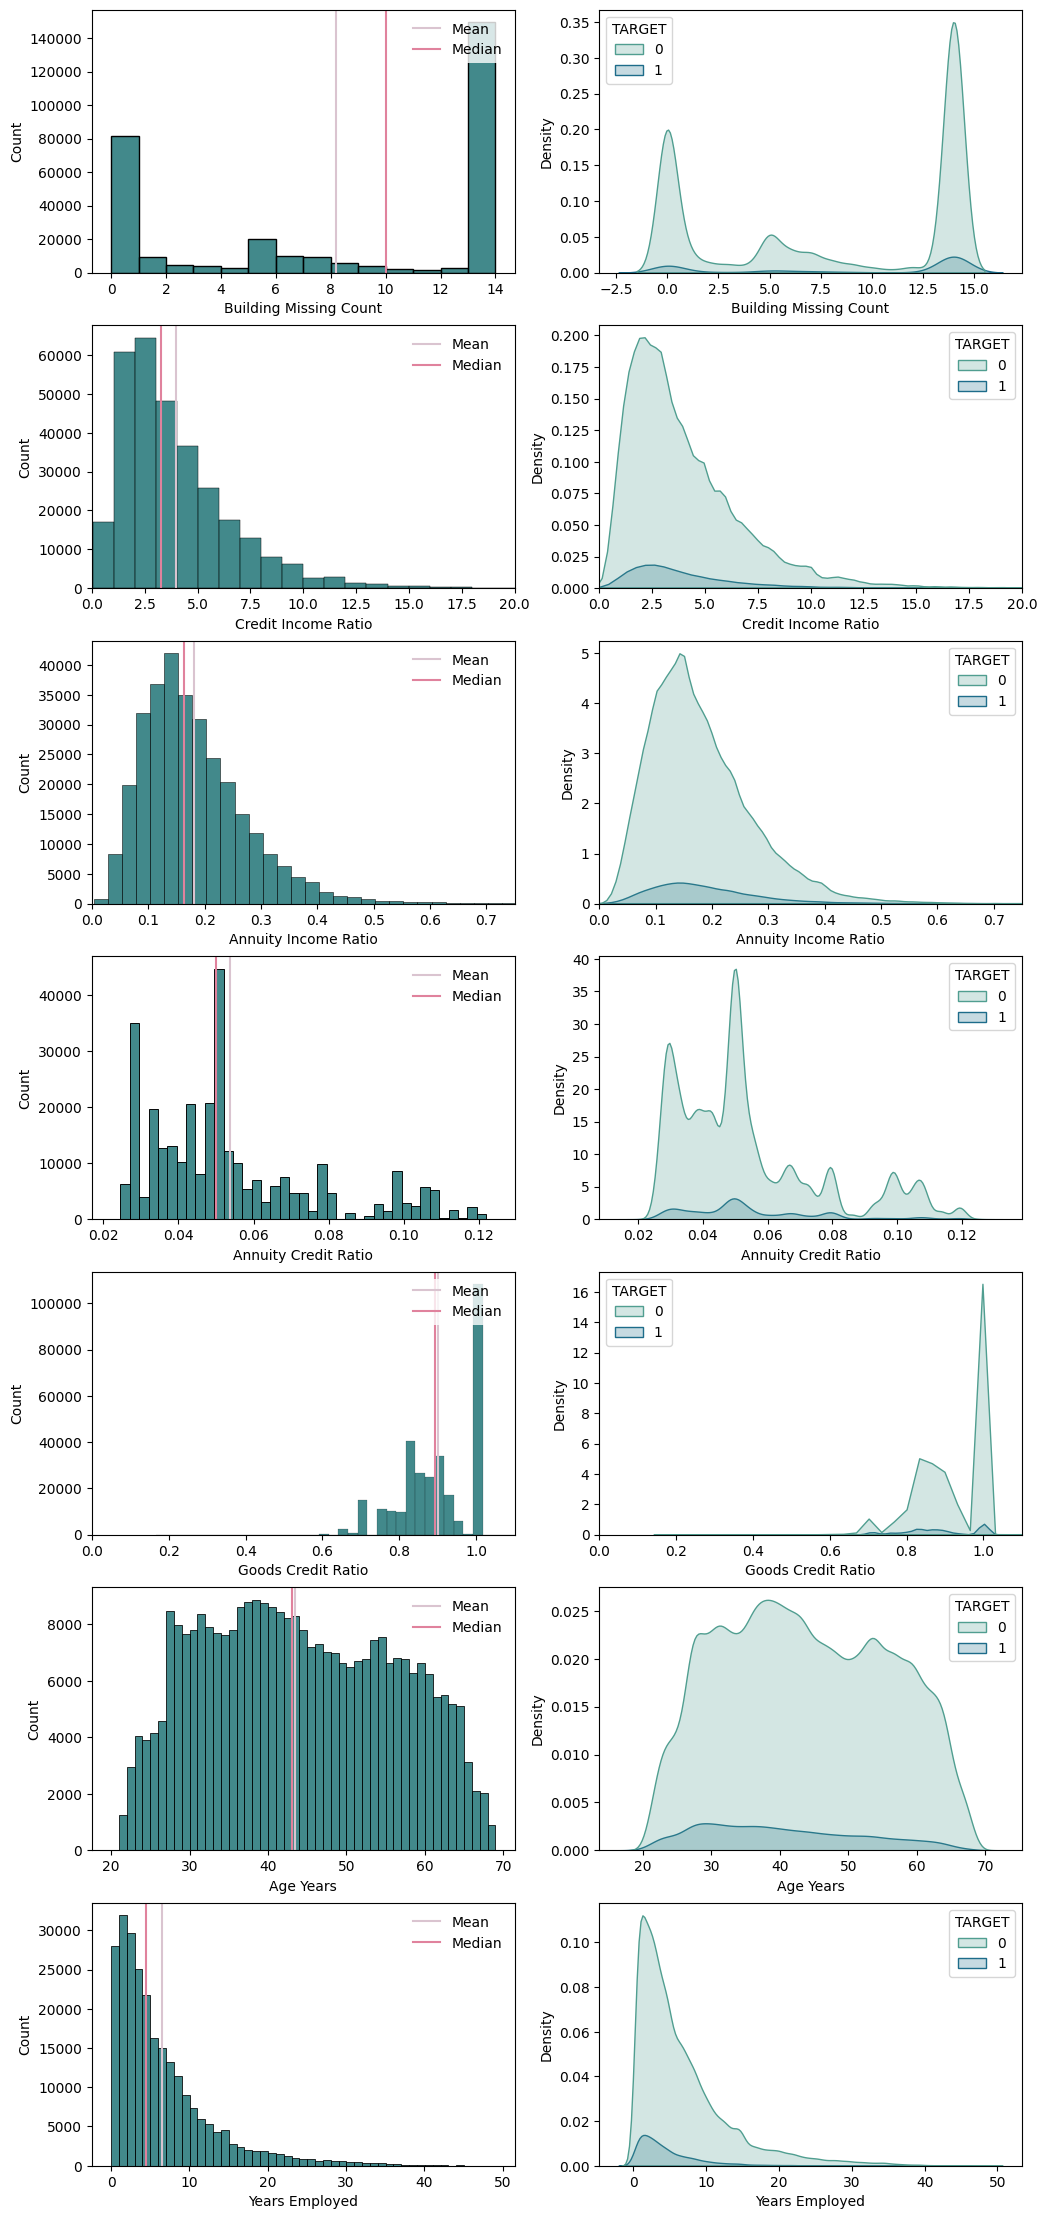

In [92]:
features = [
    'BUILDING_MISSING_COUNT',
    'CREDIT_INCOME_RATIO',
    'ANNUITY_INCOME_RATIO',
    'ANNUITY_CREDIT_RATIO',
    'GOODS_CREDIT_RATIO',
    'AGE_YEARS',
    'YEARS_EMPLOYED',
]

size = len(features)

fig, axs = plt.subplots(size, 2, figsize=(12, size * 4))

i = 0
for item in features:

    if item in ['BUILDING_MISSING_COUNT', 'CREDIT_INCOME_RATIO', 'AGE_YEARS', 'YEARS_EMPLOYED']:
        binw = 1
    elif item in ['ANNUITY_INCOME_RATIO', 'GOODS_CREDIT_RATIO']:
        binw = 0.025
    elif item in ['ANNUITY_CREDIT_RATIO']:
        binw = 0.0025
    else:
        binw = None

    title = item.replace("_", " ").title()
    ax00 = histplot_f(
        app_train[item], color=ch, color_median=cmed, color_mean=cmean, xlabel=title, binwidth=binw, ax=axs[i, 0]
    )
    ax01 = simple_kdeplot(app_train, item, xlabel=title, hue='TARGET', palette=palette, ax=axs[i, 1])
    if item in ['CREDIT_INCOME_RATIO']:
        ax00.set(xlim=(0, 20))
        ax01.set(xlim=(0, 20))
    if item in ['ANNUITY_INCOME_RATIO']:
        ax00.set(xlim=(0, 0.75))
        ax01.set(xlim=(0, 0.75))
    if item in ['GOODS_CREDIT_RATIO']:
        ax00.set(xlim=(0, 1.1))
        ax01.set(xlim=(0, 1.1))

    i += 1

There aren't any clear tendencies which can be seen apart from younger clients are more likelly to have troubles with repaying credit.

### One Hot Encoding Features

One hot encoding features to check their correlation

In [93]:
features_cat = app_train.select_dtypes(include=['object']).columns
features_cat

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
       'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE',
       'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE',
       'OCCUPATION_TYPE_GROUPED'],
      dtype='object')

In [94]:
app_train['FLAG_OWN_CAR'] = app_train['FLAG_OWN_CAR'].map({'Y': 1, 'N': 0})
app_train['FLAG_OWN_REALTY'] = app_train['FLAG_OWN_REALTY'].map({'Y': 1, 'N': 0})

In [95]:
x_num = app_train.select_dtypes(exclude='object').reset_index(drop=True)
x_cat = app_train.select_dtypes(include='object')

encoder = OneHotEncoder(sparse_output=False)
x_encoded = encoder.fit_transform(x_cat)

# create the names for the one-hot encoded categorical features
categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

# put the features into a dataframe and join with the original
# numerical features

one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)

# Dropping missing and some of rare categories
one_hot_features = one_hot_features.drop(
    [
        'EMERGENCYSTATE_MODE_nan',
        'CODE_GENDER_XNA',
        'FONDKAPREMONT_MODE_nan',
        'HOUSETYPE_MODE_nan',
        'WALLSMATERIAL_MODE_nan',
        'ORGANIZATION_TYPE_XNA',
        'NAME_TYPE_SUITE_nan',
        'NAME_TYPE_SUITE_Group of people',
        'NAME_TYPE_SUITE_Other_A',
        'NAME_INCOME_TYPE_Businessman',
        'NAME_INCOME_TYPE_Maternity leave',
        'NAME_INCOME_TYPE_Student',
        'NAME_INCOME_TYPE_Unemployed',
        'NAME_FAMILY_STATUS_Unknown',
        'NAME_HOUSING_TYPE_Co-op apartment',
        'OCCUPATION_TYPE_Unknown',
        'FONDKAPREMONT_MODE_not specified',
        'WALLSMATERIAL_MODE_Monolithic',
    ],
    axis=1,
)
app_train_enc = x_num.join(one_hot_features)

# Putting Transported column last for convience
cols = app_train_enc.columns.tolist()
cols = cols[:1] + cols[2:] + cols[1:2]

app_train_enc = app_train_enc[cols]
app_train_enc.head(10).T

,0,1,2,3,4,5,6,7,8,9
SK_ID_CURR,100002.000000,1.000030e+05,100004.000000,100006.000000,100007.000000,100008.000000,1.000090e+05,1.000100e+05,1.000110e+05,100012.000000
FLAG_OWN_CAR,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00,0.000000e+00,0.000000
FLAG_OWN_REALTY,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000
CNT_CHILDREN,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000e+00,0.000000e+00,0.000000
AMT_INCOME_TOTAL,202500.000000,2.700000e+05,67500.000000,135000.000000,121500.000000,99000.000000,1.710000e+05,3.600000e+05,1.125000e+05,135000.000000
AMT_CREDIT,406597.500000,1.293502e+06,135000.000000,312682.500000,513000.000000,490495.500000,1.560726e+06,1.530000e+06,1.019610e+06,405000.000000
AMT_ANNUITY,24700.500000,3.569850e+04,6750.000000,29686.500000,21865.500000,27517.500000,4.130100e+04,4.207500e+04,3.382650e+04,20250.000000
AMT_GOODS_PRICE,351000.000000,1.129500e+06,135000.000000,297000.000000,513000.000000,454500.000000,1.395000e+06,1.530000e+06,9.135000e+05,405000.000000
REGION_POPULATION_RELATIVE,0.018801,3.541000e-03,0.010032,0.008019,0.028663,0.035792,3.579200e-02,3.122000e-03,1.863400e-02,0.019689
DAYS_BIRTH,-9461.000000,-1.676500e+04,-19046.000000,-19005.000000,-19932.000000,-16941.000000,-1.377800e+04,-1.885000e+04,-2.009900e+04,-14469.000000


#### Correlation

For correlation calculations building features in modes and medians will be excluded, as corresponding features correlate well with each other as can be seen from graphs.

Due to limited processing power, some of highly correlated features will be removed.

In [96]:
to_remove = []
to_remove.extend(building_med)
to_remove.extend(building_mod)
for_corr = app_train_enc.iloc[:, 1:].drop(columns=to_remove)
correlation_all = correlation_f(for_corr)

In [97]:
get_correlations(correlation_all).head(20)

,Feature_1,Feature_2,Correlation
2213,DAYS_EMPLOYED,OCCUPATION_TYPE_Not employed,0.999866
20457,NAME_INCOME_TYPE_Pensioner,OCCUPATION_TYPE_Not employed,0.999626
2183,DAYS_EMPLOYED,NAME_INCOME_TYPE_Pensioner,0.999534
9742,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.997336
7218,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,0.987100
934,AMT_CREDIT,AMT_GOODS_PRICE,0.984898
15130,BUILDING_ALL_MISSING,BUILDING_OTHER_ALL_MISSING,0.980292
14971,BUILDING_MISSING_COUNT,BUILDING_OTHER_MISSING_COUNT,0.976762
15129,BUILDING_ALL_MISSING,BUILDING_OTHER_MISSING_COUNT,0.976244
6824,APARTMENTS_AVG,LIVINGAPARTMENTS_AVG,0.973052


NAME_INCOME_TYPE_Pensioner correlates with OCCUPATION_TYPE_Not employed almost perfectly, therefore it will be removed.
OBS_30_CNT_SOCIAL_CIRCLE will be removed as it correlates well with OBS_60_CNT_SOCIAL_CIRCLE.

In [98]:
get_correlations(correlation_all, threshold=-0.9, higher=False).head(20)

,Feature_1,Feature_2,Correlation
2157,DAYS_EMPLOYED,YEARS_EMPLOYED,-1.000000
19173,NAME_CONTRACT_TYPE_Cash loans,NAME_CONTRACT_TYPE_Revolving loans,-1.000000
19432,CODE_GENDER_F,CODE_GENDER_M,-0.999971
3106,FLAG_EMP_PHONE,OCCUPATION_TYPE_Not employed,-0.999846
2081,DAYS_EMPLOYED,FLAG_EMP_PHONE,-0.999755
1930,DAYS_BIRTH,AGE_YEARS,-0.999722
3076,FLAG_EMP_PHONE,NAME_INCOME_TYPE_Pensioner,-0.999515
15746,BUILDING_OTHER_ALL_MISSING,EMERGENCYSTATE_MODE_No,-0.984943
15278,BUILDING_ALL_MISSING,EMERGENCYSTATE_MODE_No,-0.965298
15582,BUILDING_OTHER_MISSING_COUNT,HOUSETYPE_MODE_block of flats,-0.959155


- Since DAYS_BIRTH and AGE_YEARS correlate well with each other, only one of them will be left - AGE_YEARS. Same for YEARS_EMPLOYED - it will be used instead of DAYS_EMPLOYED. 
- NAME_CONTRACT_TYPE_Revolving loans will be droped as it has -1 negative correlation with NAME_CONTRACT_TYPE_Cash loans. 
- FLAG_EMP_PHONE will be droped since it highly correlates with OCCUPATION_TYPE_Not employed and NAME_INCOME_TYPE_Pensioner and DAYS_EMPLOYED.
- CODE_GENDER_F will also will be droped, as it is enough to have one - CODE_GENDER_M, and they have almost perfect negative correlation with each other.
- BUILDING_OTHER_ALL_MISSING and BUILDING_ALL_MISSING has high negative correlation with EMERGENCYSTATE_MODE_No and HOUSETYPE_MODE_block of flats. Therefore, it will be removed.

In [99]:
high_corr = ['NAME_INCOME_TYPE_Pensioner', 'OBS_30_CNT_SOCIAL_CIRCLE']

high_corr_n = [
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'NAME_CONTRACT_TYPE_Revolving loans',
    'FLAG_EMP_PHONE',
    'CODE_GENDER_F',
    'BUILDING_OTHER_ALL_MISSING',
    'BUILDING_ALL_MISSING',
]

In [100]:
target_corrs = correlation_all.TARGET.sort_values(ascending=False).drop('TARGET')
target_corrs.head(10)

DAYS_BIRTH                        0.078239
OCCUPATION_TYPE_GROUPED_Manual    0.066750
REGION_RATING_CLIENT_W_CITY       0.060893
REGION_RATING_CLIENT              0.058899
NAME_INCOME_TYPE_Working          0.057481
DAYS_LAST_PHONE_CHANGE            0.054900
CODE_GENDER_M                     0.054713
NAME_EDUCATION_TYPE_SECONDARY     0.053391
DAYS_ID_PUBLISH                   0.051457
REG_CITY_NOT_WORK_CITY            0.050994
Name: TARGET, dtype: float64

In [101]:
target_corrs.tail(10).sort_values()

EXT_SOURCE_3                           -0.178919
EXT_SOURCE_2                           -0.160472
EXT_SOURCE_1                           -0.155317
AGE_YEARS                              -0.078234
YEARS_EMPLOYED                         -0.074948
GOODS_CREDIT_RATIO                     -0.065407
NAME_EDUCATION_TYPE_Higher education   -0.056593
CODE_GENDER_F                          -0.054704
NAME_INCOME_TYPE_Pensioner             -0.046209
OCCUPATION_TYPE_Not employed           -0.045983
Name: TARGET, dtype: float64

The highest absolute correlations come from external sources. After that age in years or days also is correlated to the target. We can also see that those who are longer employed tend to struggle less with repaying credit, compared to those who aren't. OCCUPATION_TYPE_GROUPED_Manual category clients correlate more with the target compared to the rest.

Overall there are no features which would stongly correlate with the target.

In [102]:
mask = (target_corrs > -0.001) & (target_corrs < 0.001)
target_corrs[mask]

HOUSETYPE_MODE_terraced house               0.000982
AMT_REQ_CREDIT_BUREAU_HOUR                  0.000930
AMT_REQ_CREDIT_BUREAU_WEEK                  0.000788
WALLSMATERIAL_MODE_Others                   0.000628
WEEKDAY_APPR_PROCESS_START_THURSDAY         0.000446
FLAG_CONT_MOBILE                            0.000370
ORGANIZATION_TYPE_Business Entity Type 1    0.000339
ORGANIZATION_TYPE_TECH                      0.000218
FLAG_DOCUMENT_20                            0.000215
ORGANIZATION_TYPE_Advertising               0.000117
ORGANIZATION_TYPE_Industry: type 7         -0.000094
ORGANIZATION_TYPE_Legal Services           -0.000236
FLAG_DOCUMENT_5                            -0.000316
OCCUPATION_TYPE_Realty agents              -0.000394
ORGANIZATION_TYPE_Housing                  -0.000464
ORGANIZATION_TYPE_Industry: type 6         -0.000652
ORGANIZATION_TYPE_Telecom                  -0.000712
ORGANIZATION_TYPE_Transport: type 2        -0.000839
ORGANIZATION_TYPE_Trade: type 5            -0.

These features have low/almost no correlation to target. Some of them are unlikely to carry any predictive power, either because they are too sparse (dummy columns for rare categories) or irrelevant document flags. They will be removed and rest will be kept.

In [103]:
no_corr = [
    'FLAG_DOCUMENT_20',
    'FLAG_DOCUMENT_5',
    'FLAG_CONT_MOBILE',
    'OCCUPATION_TYPE_Realty agents',
    'ORGANIZATION_TYPE_Advertising',
    'ORGANIZATION_TYPE_Business Entity Type 1',
    'ORGANIZATION_TYPE_Industry: type 6',
    'ORGANIZATION_TYPE_Industry: type 7',
    'ORGANIZATION_TYPE_Telecom',
    'ORGANIZATION_TYPE_Transport: type 2',
    'ORGANIZATION_TYPE_Trade: type 5',
    'ORGANIZATION_TYPE_Housing',
    'ORGANIZATION_TYPE_Legal Services',
]

### Outliers

In [104]:
selected_cols = []
excluded_cols = ['SK_ID_CURR']
excluded_cols.extend(high_corr)
excluded_cols.extend(high_corr_n)
excluded_cols.extend(no_corr)

for col in app_train.columns:
    if col in excluded_cols:
        continue

    if pd.api.types.is_integer_dtype(app_train[col]) and app_train[col].nunique() > 2:
        selected_cols.append(col)
    elif pd.api.types.is_float_dtype(app_train[col]):
        selected_cols.append(col)

selected = app_train[selected_cols]
outliers = outlier_f(selected)
outliers.count()

CNT_CHILDREN                     4272
AMT_INCOME_TOTAL                14034
AMT_CREDIT                       6562
AMT_ANNUITY                      7504
AMT_GOODS_PRICE                 14728
REGION_POPULATION_RELATIVE       8412
DAYS_REGISTRATION                 659
DAYS_ID_PUBLISH                     0
OWN_CAR_AGE                      2489
CNT_FAM_MEMBERS                  4007
REGION_RATING_CLIENT            80527
REGION_RATING_CLIENT_W_CITY     78027
HOUR_APPR_PROCESS_START          2257
EXT_SOURCE_1                        0
EXT_SOURCE_2                        0
EXT_SOURCE_3                        0
APARTMENTS_AVG                  10655
BASEMENTAREA_AVG                 7190
YEARS_BEGINEXPLUATATION_AVG      4784
YEARS_BUILD_AVG                  2154
COMMONAREA_AVG                   7942
ELEVATORS_AVG                   10420
ENTRANCES_AVG                    3882
FLOORSMAX_AVG                    5215
FLOORSMIN_AVG                     343
LANDAREA_AVG                     6888
LIVINGAPARTM

There are plenty of outliers in the dataset. Removing them will be tested in modeling part.

# End of Part One

In this part application data was explored. In the beginning missing data was investigated, in case there are some paterns. Afterwards, the charts of the features were drawn. Then the correlation was calculated between all of the features and some features were selected to be removed. Lastly, there was calculations of the outlier values done. 

While there aren't any strong correlations related to the target, we can still see some tendencies. For example, we can see that younger adults struggle more often to repay the credit, also those who weren't employed for long time. Manual and Service occupation types are more likelly to have the target compared to rest. Also there is negative correlation between the target and external sources. 

In part 2 of this project exploring additional data provided will be explored.